# Download and prepare `SW_IN` (2004-2026.09)

**notebook version**: `11` (22 Oct 2026)

## ℹ️ About this notebook

Downloads screened `SW_IN` from InfluxDB, merges the sources into one series, corrects the 2012
logger faults and the nighttime offset, gap-fills, and writes the product to the external data
folder.

**Output columns**

- `SW_IN_T1_47_1_gfXG`: gap-filled series (W m⁻², complete, non-negative)
- `FLAG_SW_IN_T1_47_1_ISFILLED`: `0` measured, `>0` filled (codes in `FLAG_LEGEND`)

**Fill quality differs by period.** 2004-2018 has two drivers, NABEL on the same tower and
MeteoSwiss Lägern 2.5 km away. From 2019 only Lägern remains, so fills rest on the more distant
sensor.

`InfluxIO` needs `influxdb-client`, which `uv sync` installs through the `diive[db]` extra.

***

## 📇 Data sources

**Series**

- `SW_IN_T1_47_1`: ETH, 47 m, the product series. `mst` screening 2005-2021, `diive` 2022-2026.
- `SW_IN_NABEL_T1_49_1`: NABEL, 49 m, same tower, 2004-2018. Gap-filling driver.
- `SW_IN_LAE_MS`: MeteoSwiss Lägern, 2.5 km, 845 m, 2004-2026. Gap-filling driver, from
  `10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb`.

Both drivers are used as measured. Gap-filling uses XGBoost; the gap-filler adds potential
radiation and timestamp features itself.

**Screening**

- `mst`: ETH data, screened with the deprecated MeteoScreeningTool
- `diive`: ETH data and [NABEL](https://www.bafu.admin.ch/bafu/en/home/topics/air/luftbelastung/national-air-pollution-monitoring-network--nabel-.html), screened with [diive](https://github.com/holukas/diive)

## ⏱️ Timestamp convention

The database stores UTC `TIMESTAMP_END`. `InfluxIO` shifts it by `TIMEZONE_OFFSET_TO_UTC_HOURS` to
local time, and `TimestampSanitizer(output_middle_timestamp=True)` converts it to
`TIMESTAMP_MID`, which the rest of the notebook uses. `START` and `STOP` are local time.

***

## ⚙️ Settings

### Data settings

In [1]:
DIRCONF = r'F:\dev\poet\configs'  # database connection configs
# DIRCONF = r'P:\Flux\RDS_calculations\_scripts\_configs\configs'  # alternative location
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # local time UTC+01:00 (CET)
REQUIRED_TIME_RESOLUTION = '30min'  # TimestampSanitizer raises if the data disagree
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389  # CH-LAE

# Last record (TIMESTAMP_MID). The file names say 2026.09; the export check asserts it.
PERIOD_END = '2026-09-30 23:45:00'

# Output, in the external data folder, same numeric prefix as this notebook
OUTNAME = "01_METEO_SW_IN_GAPFILLED_2004-2026.09"
OUTPATH = r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS"

# Reference: MeteoSwiss Lägern, written by 10_REFERENCE/MeteoSwiss_LAE_2004-2026.09.ipynb
REFPATH = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet")
REFCOL = "SW_IN_LAE_MS"

# Site maintenance record (GIN export), stored beside the workflow folder
FIELDBOOK = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
             r"\fieldbook_gin\CH-LAE-laegeren-export_20261022.csv")

# Every surviving logger program that measures this sensor: the three CR10X programs with the
# CNR1 (2005-2006) and the CR1000 program of 2016. None survives from May 2006 to January 2016.
PROGRAMS_BEFORE = [
    r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
    r"\csi_loggerscripts\LAEGEREN.20050818.CSI",
    r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
    r"\csi_loggerscripts\LAEGEREN.20050914.CSI",
    r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
    r"\csi_loggerscripts\LAEGEREN.20060524.csi",
]
PROGRAM_AFTER = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
                 r"\logger_scripts\ch-lae_idl_t1_47_1-Version_20160118\CH-LAE_iDL_T1_47_1.CR1")


### Imports

In [2]:
from datetime import datetime
from pathlib import Path
import importlib.metadata
import html
import re
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme('notebook')

import diive as dv
from diive.core.io.db.influx import InfluxIO  # diive's in-house InfluxDB engine (via the diive[db] extra)
from diive.core.times.times import TimestampSanitizer

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-23 12:21:04
diive version: v0.93.0


In [3]:
# Result flags of SWINGapFillerXGBoost, see the class docstring.
FLAG_LEGEND = {
    0: '0 = observed',
    1: '1 = daytime gap, filled by the XGBoost model',
    2: '2 = daytime gap, filled by the timestamp-only fallback model (a driver was missing)',
    3: '3 = nighttime gap, set to zero by physics',
    4: '4 = daytime gap, filled by clearness-index interpolation',
}

### Captions


In [4]:
# Caption helpers, copied as-is from notebook 02. Defined above their first use.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure with a layout engine makes room for a caption itself. The heatmaps diive builds have
    no engine, and a caption placed in one lands on top of the tick labels; for those the figure
    is extended downwards and every axes moved up by the same amount, so the drawing keeps its
    size and position and the caption gets a free strip below it.
    """
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    # An engine that still lays the figure out at draw time can make room for a caption itself.
    # plt.tight_layout() does NOT leave one: it executes once and leaves a PlaceHolderLayoutEngine
    # that never runs again, so a caption handed to supxlabel there lands on top of the tick
    # labels. Those figures take the manual branch below.
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')


### Plot helpers

In [5]:
# Diagnostic plots for the gap-filling runs. Each helper builds its own caption from its
# arguments and data, so every call site gets a caption that matches it.

def plot_gapfill_panels(results, label, ylabel=r'$\mathrm{W\ m^{-2}}$', figsize=(16, 7)):
    """Three stacked panels: measured only, the final series, and the fills on their own.

    The third panel is the one to look at. Fills are shown against a blank background, so
    a fill that sits at the wrong level, or a block of fills where there should be none,
    is immediately visible instead of being hidden under the measured series.
    """
    gapfilled = results.gapfilled
    flag = results.flag
    _plotdf = pd.DataFrame({
        'observed': gapfilled.where(flag == 0),
        'gapfilled': gapfilled,
        'gap values': gapfilled.where(flag > 0),
    })
    axs = _plotdf.plot(subplots=True, figsize=figsize, x_compat=True, alpha=.9,
                       title=f"{label}: measured, gap-filled, fills only", legend=True)
    for ax in axs:
        ax.set_ylabel(ylabel)
    plt.tight_layout()
    fig = axs[0].get_figure()
    figcap(fig, f"{label}. Top: measured records only. Middle: the exported series. Bottom: the "
                f"{int((flag > 0).sum()):,} filled records ({100 * (flag > 0).mean():.1f} % of this "
                f"period) alone, where a fill at an implausible level stands out.")
    return fig


def fill_stats_by_year(flag, label, legend=None):
    """Records per year and flag, plus a stacked bar chart of the filled ones."""
    legend = legend or FLAG_LEGEND
    tab = (pd.crosstab(flag.index.year, flag)
             .rename(columns=lambda f: legend.get(f, f))
             .rename_axis(index='year', columns=None))
    filled = tab.drop(columns=[c for c in tab.columns if str(c).startswith('0 =')],
                      errors='ignore')
    if not filled.empty and filled.to_numpy().sum() > 0:
        ax = filled.plot(kind='bar', stacked=True, figsize=(14, 4),
                         title='Filled records per year')
        ax.set_ylabel('records')
        ax.legend(fontsize=8)
        plt.tight_layout()
        _worst = filled.sum(axis=1).idxmax()
        _totals = filled.sum(axis=1)
        _quiet = int((_totals < 100).sum())
        _first = flag.index[flag == 0][0]
        _pre = int(((flag.index < _first) & (flag.index.year == _worst)).sum())
        figcap(ax.get_figure(),
               f"filled records per year and method for {label}. The most filled year is {_worst} "
               f"({int(_totals.max()):,} records, {_pre:,} of them before the first measured "
               f"record); {_quiet} of {len(_totals)} years have fewer than 100 filled records.")
    tabcap(f"records per year and provenance code for {label}; each row sums to the half-hours "
           f"of that year")
    return tab


def plot_fill_overview(series, flag, label, ylabel=r'$\mathrm{W\ m^{-2}}$'):
    """Four-panel overview of the final series: where the fills are and how they behave.

    Panels: flag over date/time-of-day; monthly means of the full series against the
    measured-only series (a gap between the two lines means the fills are biased);
    and the share of filled records per month.
    """
    fig = plt.figure(figsize=(18, 9), dpi=100, layout='constrained')
    gs = gridspec.GridSpec(2, 2, figure=fig)
    fig.suptitle(f'Gap-filling overview: {label}', fontsize=15)

    ax = fig.add_subplot(gs[:, 0])
    dv.plotting.HeatmapDateTime(series=flag.astype(float)).plot(
        ax=ax, cb_digits_after_comma=0, zlabel='flag',
        format_style=dv.plotting.FormatStyle(title='Flag (0 = measured)', title_fontsize=11))

    measured = series.where(flag == 0)
    ax = fig.add_subplot(gs[0, 1])
    series.resample('MS').mean().plot(ax=ax, label='all records', lw=1.2)
    measured.resample('MS').mean().plot(ax=ax, label='measured only', lw=1.2, ls='--')
    ax.set_title('Monthly means', fontsize=11)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

    ax = fig.add_subplot(gs[1, 1])
    share = (flag > 0).resample('MS').mean() * 100
    ax.fill_between(share.index, share.values, step='mid', alpha=.7)
    ax.set_title('Share of filled records per month', fontsize=11)
    ax.set_ylabel('%')

    _gap = (series.resample('MS').mean() - measured.resample('MS').mean()).abs().max()
    figcap(fig, f"fills of {label}. Left: provenance code by date and time of day. Top right: "
                f"monthly means of the complete series and of measured records only, at most "
                f"{_gap:.1f} W m-2 apart in any month. Bottom right: share of each month that is "
                f"filled.")
    return fig


def plot_pred_vs_measured(model, label, unit=r'$\mathrm{W\ m^{-2}}$'):
    """Predicted against measured on the held-out test set, plus residuals.

    `gapfilled` equals the measurement wherever the flag is 0, so only the test records in
    `daytime_model_.traintest_details_`, which the model never saw, validate the fills.
    """
    if model is None:
        print("No model available (no daytime gaps) - nothing to validate.")
        return
    test = model.traintest_details_['test_df']
    measured = test[model.target_col].values
    predicted = model.model_.predict(test.drop(columns=model.target_col))
    residual = predicted - measured
    rmse = float(np.sqrt((residual ** 2).mean()))
    bias = float(residual.mean())

    fig, axs = plt.subplots(ncols=2, figsize=(13, 5.5), dpi=100, layout='constrained')
    fig.suptitle(f"{label} daytime model  (held-out test set, n={len(test):,})", fontsize=13)

    axs[0].hexbin(measured, predicted, gridsize=60, mincnt=1, bins='log', cmap='viridis')
    lim = [float(min(measured.min(), predicted.min())), float(max(measured.max(), predicted.max()))]
    axs[0].plot(lim, lim, 'r-', lw=1.2, label='1:1')
    axs[0].set_xlabel(f'measured {unit}')
    axs[0].set_ylabel(f'predicted {unit}')
    axs[0].set_title(f'RMSE {rmse:.2f}   bias {bias:+.2f}', fontsize=11)
    axs[0].legend(fontsize=8)

    axs[1].hexbin(predicted, residual, gridsize=60, mincnt=1, bins='log', cmap='viridis')
    axs[1].axhline(0, color='r', lw=1.2)
    axs[1].set_xlabel(f'predicted {unit}')
    axs[1].set_ylabel(f'residual (predicted - measured) {unit}')
    axs[1].set_title('Residuals', fontsize=11)
    figcap(fig, f"the {label} daytime model on the {len(test):,} records held out of training. "
                f"Left: predicted against measured with the 1:1 line (RMSE {rmse:.1f} W m-2, bias "
                f"{bias:+.2f} W m-2). Right: residual against prediction; the widening cone is "
                f"expected because a radiation error scales with the value.")
    return fig


def plot_feature_importances(results, label, top=12):
    """The drivers the model actually used, as a bar chart rather than only a table.

    A gap-filling model that leans almost entirely on the timestamp features is filling with
    climatology, whatever its scores say. This is the view that shows it at a glance.
    """
    imp = results.feature_importances.copy()
    _col = next((c for c in ('PERM_IMPORTANCE', 'IMPORTANCE', 'importance')
                 if c in imp.columns), imp.columns[0])
    imp = imp.sort_values(_col, ascending=False).head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(imp) + 1.6), dpi=100, layout='constrained')
    ax.barh(imp.index.astype(str), imp[_col], color='#1565C0')
    ax.set_xlabel(_col)
    ax.set_title(f'Driver importance: {label}', fontsize=12)
    ax.grid(axis='x', alpha=0.3)
    _top_name = str(imp.index[-1])
    figcap(fig, f"the {min(top, len(imp))} most important drivers of the {label} daytime model, "
                f"ranked by {_col}; the strongest is {_top_name}. A model led by the timestamp "
                f"features would fill with climatology.")
    return fig

### 🔌 Connect to database

In [6]:
dbc = InfluxIO(dirconf=DIRCONF)

> Reading configuration files was successful.

v Connection to database works.

***

## ⬇️ `NABEL` data (2004-2018) and ETH data (2022-2026) from `diive` meteoscreening

### Download

In [7]:
%%time

BUCKET = f'ch-lae_processed'
FIELDS = ['SW_IN_NABEL_T1_49_1', 'SW_IN_T1_47_1']
MEASUREMENTS = ['SW']
START = '2004-01-01 00:00:01'
STOP = '2026-10-01 00:00:01'  # includes the record ending 1 Oct 00:00
DATA_VERSION = 'meteoscreening_diive'

swin_diive, _, _ = dbc.download(
    bucket=BUCKET,
    measurements=MEASUREMENTS,
    fields=FIELDS,
    start=START,  # Download data starting with this date (the start date itself IS included),
    stop=STOP,  # Download data before this date (the stop date itself IS NOT included),
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version=DATA_VERSION
)

> DOWNLOADING from bucket ch-lae_processed: variables ['SW_IN_NABEL_T1_49_1', 'SW_IN_T1_47_1'] 
from measurements ['SW'], data version ['meteoscreening_diive'], between 2004-01-01 00:00:01 and 
2026-10-01 00:00:01 (timezone offset to UTC 1)

> Downloaded data for 2 variables:

> <-- SW_IN_T1_47_1: 83,150 records from 2022-01-01 00:30:00 to 2026-10-01 00:00:00, time 
resolution 30min (freq tag: 30min)

> <-- SW_IN_NABEL_T1_49_1: 262,774 records from 2004-01-01 00:30:00 to 2019-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

CPU times: total: 6.42 s
Wall time: 12.5 s


In [8]:
swin_diive

,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1
TIMESTAMP_END,,
2004-01-01 00:30:00,NaN,0.0
2004-01-01 01:00:00,NaN,0.0
2004-01-01 01:30:00,NaN,0.0
2004-01-01 02:00:00,NaN,0.0
2004-01-01 02:30:00,NaN,0.0
...,...,...
2026-09-30 22:00:00,0.0,NaN
2026-09-30 22:30:00,0.0,NaN
2026-09-30 23:00:00,0.0,NaN


### Sanitize timestamp

In [9]:
swin_diive = TimestampSanitizer(
    data=swin_diive,
    output_middle_timestamp=True,
    nominal_freq=REQUIRED_TIME_RESOLUTION,  # raises ValueError if the data are not 30MIN
).get()
swin_diive

,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,0.0
2004-01-01 00:45:00,NaN,0.0
2004-01-01 01:15:00,NaN,0.0
2004-01-01 01:45:00,NaN,0.0
2004-01-01 02:15:00,NaN,0.0
...,...,...
2026-09-30 21:45:00,0.0,NaN
2026-09-30 22:15:00,0.0,NaN
2026-09-30 22:45:00,0.0,NaN


***

## ⬇️ Data from `mst` meteoscreening (2004-2021)

### Download

In [10]:
%%time

BUCKET = f'ch-lae_processed'
FIELDS = ['SW_IN_T1_47_1']
MEASUREMENTS = ['SW']
START = '2004-01-01 00:00:01'
STOP = '2022-01-01 00:00:01'
DATA_VERSION = 'meteoscreening_mst'

swin_mst, _, _ = dbc.download(
    bucket=BUCKET,
    measurements=MEASUREMENTS,
    fields=FIELDS,
    start=START,  # Download data starting with this date (the start date itself IS included),
    stop=STOP,  # Download data before this date (the stop date itself IS NOT included),
    timezone_offset_to_utc_hours=TIMEZONE_OFFSET_TO_UTC_HOURS,
    data_version=DATA_VERSION
)

> DOWNLOADING from bucket ch-lae_processed: variables ['SW_IN_T1_47_1'] from measurements ['SW'], 
data version ['meteoscreening_mst'], between 2004-01-01 00:00:01 and 2022-01-01 00:00:01 (timezone 
offset to UTC 1)

> Downloaded data for 1 variables:

> <-- SW_IN_T1_47_1: 282,894 records from 2005-09-14 11:30:00 to 2022-01-01 00:00:00, time 
resolution 30min (freq tag: 30min)

CPU times: total: 5 s
Wall time: 8.22 s


In [11]:
swin_mst

,SW_IN_T1_47_1
TIMESTAMP_END,
2005-09-14 11:30:00,0.000000
2005-09-14 12:00:00,25.692612
2005-09-14 13:30:00,645.754150
2005-09-14 14:00:00,314.615936
2005-09-14 14:30:00,220.304276
...,...
2021-12-31 22:00:00,-9.935194
2021-12-31 22:30:00,-10.250348
2021-12-31 23:00:00,-9.810373


### Sanitize timestamp

In [12]:
swin_mst = TimestampSanitizer(
    data=swin_mst,
    output_middle_timestamp=True,
    nominal_freq=REQUIRED_TIME_RESOLUTION,  # raises ValueError if the data are not 30MIN
).get()
swin_mst

,SW_IN_T1_47_1
TIMESTAMP_MIDDLE,
2005-09-14 11:15:00,0.000000
2005-09-14 11:45:00,25.692612
2005-09-14 12:15:00,NaN
2005-09-14 12:45:00,NaN
2005-09-14 13:15:00,645.754150
...,...
2021-12-31 21:45:00,-9.935194
2021-12-31 22:15:00,-10.250348
2021-12-31 22:45:00,-9.810373


***

## ❇️ Merge data

The `diive`-screened ETH data (2022-2026) are the main series. Gaps before 2022 are filled from
the `mst` screening.

In [13]:
# Merge data on index
swin_2004_2026 = swin_diive.copy()
swin_2004_2026['SW_IN_T1_47_1'] = swin_2004_2026['SW_IN_T1_47_1'].combine_first(swin_mst['SW_IN_T1_47_1'])
swin_2004_2026

,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,0.0
2004-01-01 00:45:00,NaN,0.0
2004-01-01 01:15:00,NaN,0.0
2004-01-01 01:45:00,NaN,0.0
2004-01-01 02:15:00,NaN,0.0
...,...,...
2026-09-30 21:45:00,0.0,NaN
2026-09-30 22:15:00,0.0,NaN
2026-09-30 22:45:00,0.0,NaN


### Sanitize timestamp

In [14]:
swin_2004_2026 = TimestampSanitizer(data=swin_2004_2026, output_middle_timestamp=True).get()
swin_2004_2026

,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,0.0
2004-01-01 00:45:00,NaN,0.0
2004-01-01 01:15:00,NaN,0.0
2004-01-01 01:45:00,NaN,0.0
2004-01-01 02:15:00,NaN,0.0
...,...,...
2026-09-30 21:45:00,0.0,NaN
2026-09-30 22:15:00,0.0,NaN
2026-09-30 22:45:00,0.0,NaN


### 📊 Plot: heatmap of the merged record

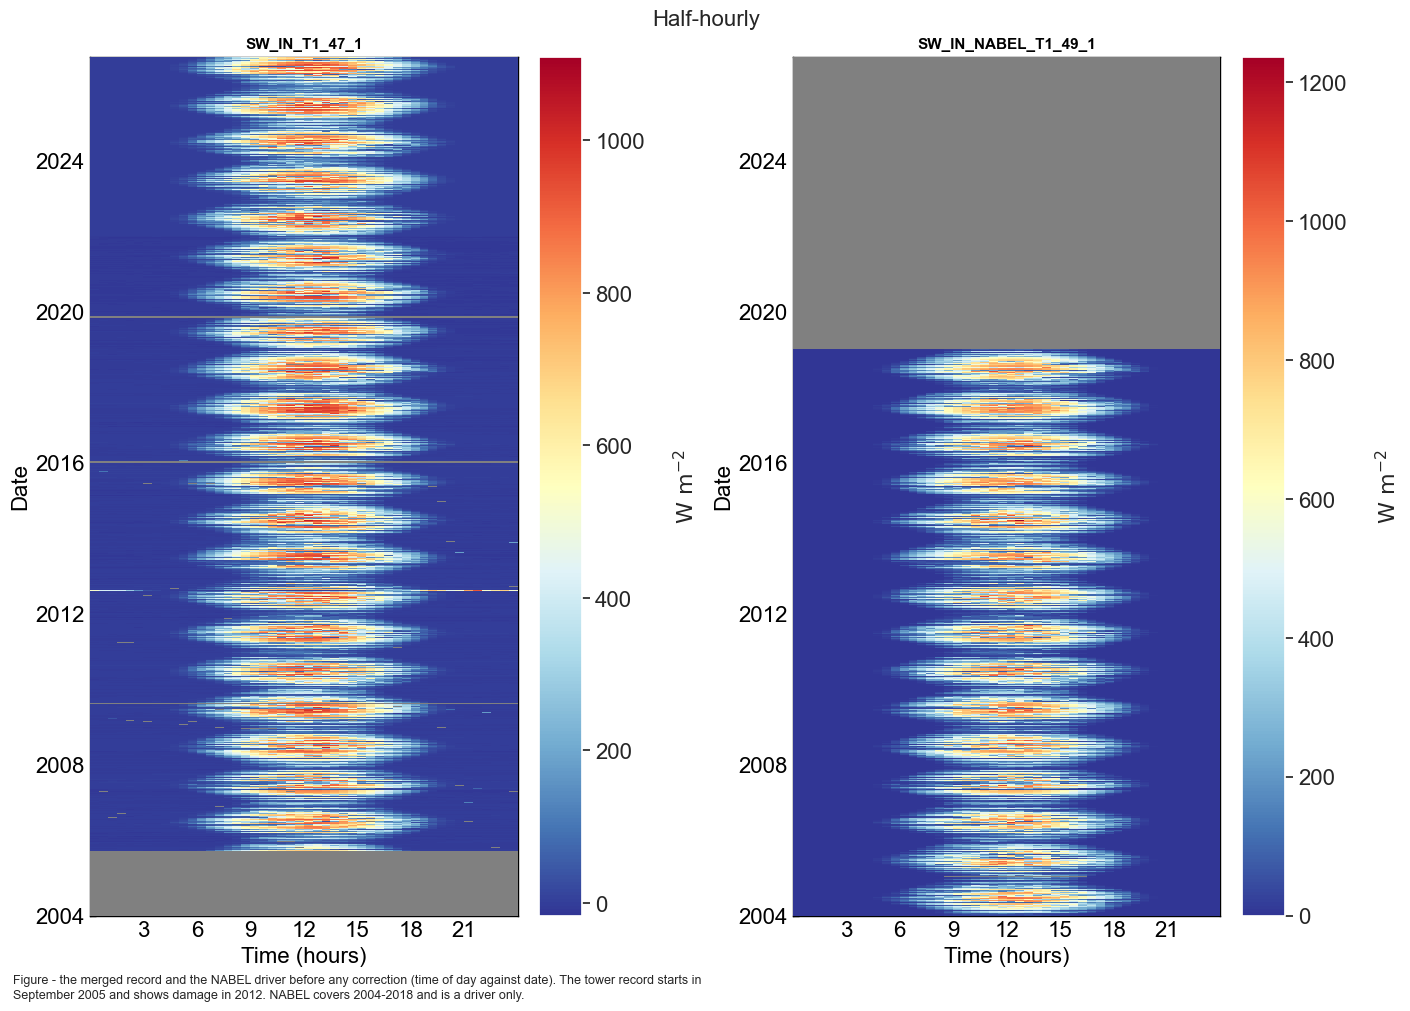

In [15]:
fig, axs = plt.subplots(ncols=2, figsize=(14, 10), dpi=100, layout="constrained")
fig.suptitle(f'Half-hourly', fontsize=16)
dv.plotting.HeatmapDateTime(series=swin_2004_2026['SW_IN_T1_47_1']).plot(
    ax=axs[0], cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
    format_style=dv.plotting.FormatStyle(title="SW_IN_T1_47_1", title_fontsize=11))
dv.plotting.HeatmapDateTime(series=swin_2004_2026['SW_IN_NABEL_T1_49_1']).plot(
    ax=axs[1], cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
    format_style=dv.plotting.FormatStyle(title="SW_IN_NABEL_T1_49_1", title_fontsize=11))
figcap(fig, "the merged record and the NABEL driver before any correction (time of day against "
            "date). The tower record starts in September 2005 and shows damage in 2012. NABEL "
            "covers 2004-2018 and is a driver only.")

### 📊 Plot: where the record comes from

Which source covers which part of the record, before any correction.

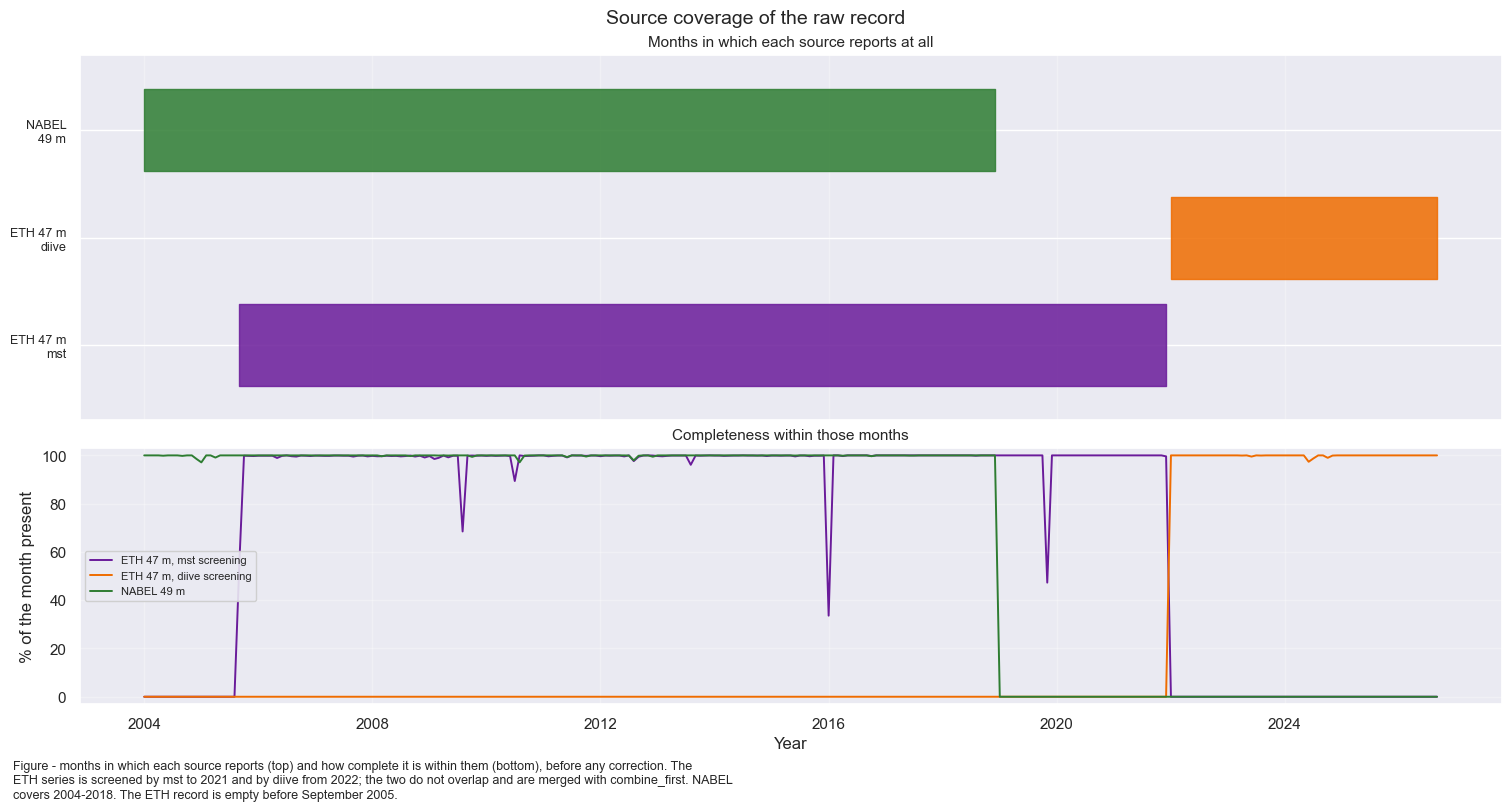

In [16]:
# Which source covers which part of the record, and how completely. Drawn from the two downloads
# as they arrived, so this is the raw availability the rest of the notebook has to work with.
_avail = pd.DataFrame({
    'ETH 47 m, diive screening': swin_diive['SW_IN_T1_47_1'].notna(),
    'ETH 47 m, mst screening': swin_mst['SW_IN_T1_47_1'].reindex(
        swin_2004_2026.index).fillna(False).astype(bool),
    'NABEL 49 m': swin_2004_2026['SW_IN_NABEL_T1_49_1'].notna(),
}, index=swin_2004_2026.index)
_avail['ETH 47 m, mst screening'] = swin_mst['SW_IN_T1_47_1'].reindex(
    swin_2004_2026.index).notna()
_monthly = _avail.resample('MS').mean() * 100

fig, axs = plt.subplots(nrows=2, figsize=(15, 8), dpi=100, layout='constrained',
                        height_ratios=[2, 1.4], sharex=True)
fig.suptitle('Source coverage of the raw record', fontsize=14)

for _i, (_name, _colour) in enumerate([('ETH 47 m, mst screening', '#6A1B9A'),
                                       ('ETH 47 m, diive screening', '#EF6C00'),
                                       ('NABEL 49 m', '#2E7D32')]):
    _present = _monthly[_name] > 0
    axs[0].fill_between(_monthly.index, _i - 0.38, _i + 0.38,
                        where=_present, color=_colour, alpha=0.85, step='mid')
axs[0].set_yticks(range(3))
# The row labels name the sources, so no legend is needed on this panel - one there sat
# across the lower panel's title.
axs[0].set_yticklabels(['ETH 47 m\nmst', 'ETH 47 m\ndiive', 'NABEL\n49 m'], fontsize=9)
axs[0].set_ylim(-0.7, 2.7)
axs[0].set_title('Months in which each source reports at all', fontsize=11)
axs[0].grid(axis='x', alpha=0.3)

for _name, _colour in [('ETH 47 m, mst screening', '#6A1B9A'),
                       ('ETH 47 m, diive screening', '#EF6C00'),
                       ('NABEL 49 m', '#2E7D32')]:
    axs[1].plot(_monthly.index, _monthly[_name], color=_colour, lw=1.4, label=_name)
axs[1].set_ylabel('% of the month present')
axs[1].set_xlabel('Year')
axs[1].set_ylim(-3, 103)
axs[1].set_title('Completeness within those months', fontsize=11)
axs[1].grid(alpha=0.3)
axs[1].legend(fontsize=8, loc='center left', framealpha=0.9)

figcap(fig, "months in which each source reports (top) and how complete it is within them "
            "(bottom), before any correction. The ETH series is screened by mst to 2021 and by "
            "diive from 2022; the two do not overlap and are merged with combine_first. NABEL "
            "covers 2004-2018. The ETH record is empty before September 2005.")

***

## ✴️ Corrections

### Timestamp shift in August 2012
**Info from fieldbook entry 17 Aug 2012:**
>   adjusted the logger date and time. On Servertime (Computer System Time) 17.08.2012 12:31.42 the loggertime was 16.08.2012 08:06:00. Synchronized time at 17.08.2012 11:40:00 servertime. The logger data aquisition on the moxa embedded was restarted

#### 📊 Plot: the August 2012 clock shift, panel by panel

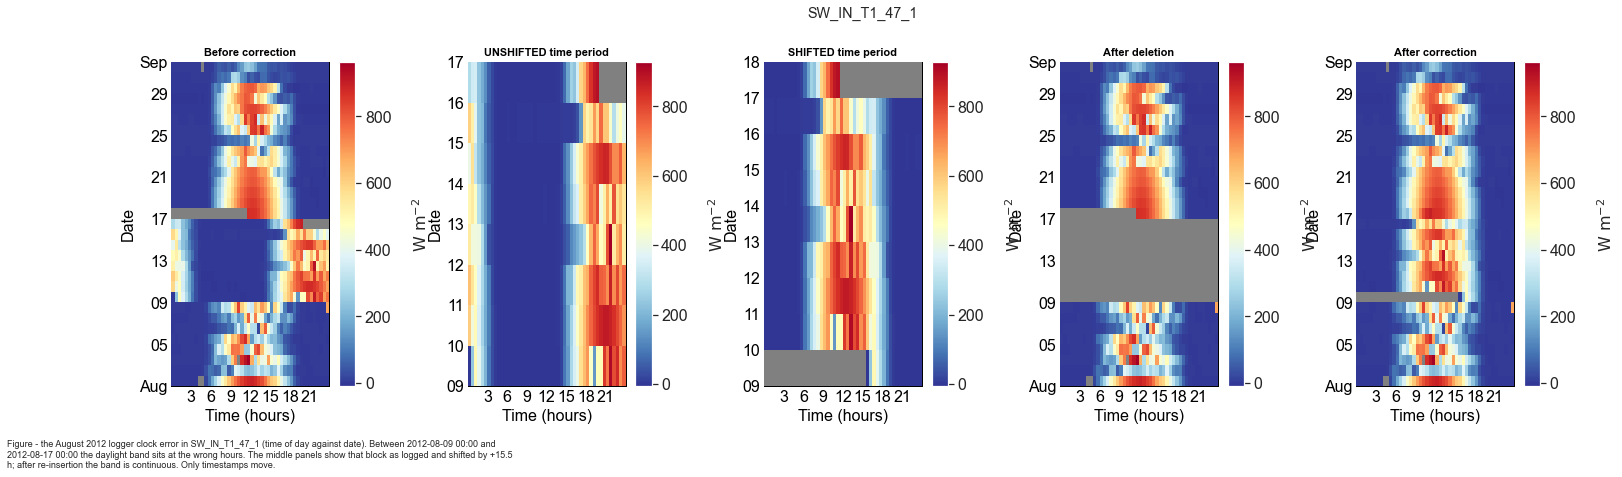

In [17]:
AFFECTED_VARS = ['SW_IN_T1_47_1']
_df = swin_2004_2026.copy()

for av in AFFECTED_VARS:
    fig = plt.figure(figsize=(24, 6), dpi=72)
    fig.suptitle(f"{av}")
    gs = gridspec.GridSpec(1, 5)  # rows, cols
    gs.update(wspace=0.5, hspace=1, left=.1, right=.9, top=.85, bottom=.1)
    ax_before = fig.add_subplot(gs[0, 0])
    ax_unshifted = fig.add_subplot(gs[0, 1])
    ax_shifted = fig.add_subplot(gs[0, 2])
    ax_after = fig.add_subplot(gs[0, 3])
    ax_corrected = fig.add_subplot(gs[0, 4])

    # Show time period around issue, before correction
    _show_locs = (_df.index >= '2012-08-01 00:00') & (_df.index <= '2012-09-01 00:00')
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_before, cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title="Before correction", title_fontsize=11))

    # Get shifted time period
    _series_corrected = _df.loc[_show_locs, av].copy()
    # Identify shifted time period
    ISSUE_START = '2012-08-09 00:00'
    ISSUE_END = '2012-08-17 00:00'
    _shifted_locs = (_df.index >= ISSUE_START) & (_df.index <= ISSUE_END)
    _series_shifted = _df.loc[_shifted_locs, av].copy()
    _series_shifted = _series_shifted.dropna()
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_unshifted, cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title="UNSHIFTED time period", title_fontsize=11))

    # Shift SW_IN by 15.5 hours during shifted time period, create corrected time series
    _series_shifted.index = _series_shifted.index + pd.Timedelta(hours=15.5)
    dv.plotting.HeatmapDateTime(series=_series_shifted).plot(
        ax=ax_shifted, cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title="SHIFTED time period", title_fontsize=11))

    # Delete data between start of issue and the last timestamp of shifted data
    _overwrite_locs = (_df.index >= ISSUE_START) & (_df.index <= _series_shifted.index[-1])
    _df.loc[_overwrite_locs, av] = np.nan
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_after, cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title="After deletion", title_fontsize=11))

    # Fill in corrected values
    _df.loc[_overwrite_locs, av] = _series_shifted
    dv.plotting.HeatmapDateTime(series=_df.loc[_show_locs, av]).plot(
        ax=ax_corrected, cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title="After correction", title_fontsize=11))

    figcap(fig, f"the August 2012 logger clock error in {av} (time of day against date). Between "
                f"{ISSUE_START} and {ISSUE_END} the daylight band sits at the wrong hours. The "
                f"middle panels show that block as logged and shifted by +15.5 h; after "
                f"re-insertion the band is continuous. Only timestamps move.")

In [18]:
swin_2004_2026 = _df.copy()
swin_2004_2026

,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,0.0
2004-01-01 00:45:00,NaN,0.0
2004-01-01 01:15:00,NaN,0.0
2004-01-01 01:45:00,NaN,0.0
2004-01-01 02:15:00,NaN,0.0
...,...,...
2026-09-30 21:45:00,0.0,NaN
2026-09-30 22:15:00,0.0,NaN
2026-09-30 22:45:00,0.0,NaN


### Power failure, late July to mid August 2012

Aligning `SW_IN_T1_47_1` against NABEL day by day and searching for the best time lag gives:

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-07-28 | 0 | 37 | 37 |
| 2012-07-31 | 0 | 70 | 70 |
| 2012-08-02 | 0 | 156 | 156 |
| 2012-08-06 | -25.0 h | 181 | 208 |
| 2012-08-09 | -32.5 h | 116 | 467 |
| **2012-08-10** | **+15.5 h** | **60** | 565 |
| **2012-08-14** | **+15.5 h** | **42** | 503 |
| **2012-08-16** | **+15.5 h** | **55** | 420 |
| 2012-08-17 | -24.5 h | 122 | 249 |
| 2012-08-18 | 0 | 8 | 8 |

Two faults:

- **10-16 August** locks onto `+15.5 h` and the RMSE falls from about 500 to 42-60 W m⁻². This is
  the logger clock, corrected above.
- **29 July to 9 August** degrades steadily and no time shift repairs it. The best lags of about
  ±24 h are aliases of the daily cycle and still leave 115-230 W m⁻². 17 August is transitional.

The fieldbook dates the repair to the day the degradation ends:

> **09.08.2012** Fixed the power problem on the tower: replaced battery and replaced some fuses
> (there were many falsely placed or broken) and replaced the whole power supply
>
> **10.08.2012** Some problems remain with logger, maybe it's the WLAN (could not log in the last
> two weeks), restared programs

"Could not log in the last two weeks" puts the onset near 27 July. `TA_T1_47_1` degrades over the
same window and no lag repairs it either, which points to a supply fault upstream of both sensors.

The records cannot be repaired. Over 29 July to 9 August the daytime mean is 309 W m⁻² at 47 m
against 402 W m⁻² at NABEL, half-hours differ by up to 933 W m⁻², and the sign of the error
changes from day to day. They are deleted and gap-filled from the drivers.

The windows below are on the **corrected** time axis. The first runs to 10 August 15:30 because
the shift moves the 9 August readings forward by 15.5 h; the second covers the tail after the last
shifted value; the third is the period below.

### Storm damage, late October to early November 2012

| date | best lag | RMSE at best lag | RMSE at zero lag |
|---|---|---|---|
| 2012-10-27 | 0 | 6.4 | 6.4 |
| 2012-10-28 | 0 | 143.3 | 143.3 |
| 2012-10-30 | 0 | 214.4 | 214.4 |
| 2012-11-05 | -3.0 h | 177.1 | 182.3 |
| 2012-11-08 | 0 | 71.4 | 71.4 |
| 2012-11-10 | 0 | 15.6 | 15.6 |

No time shift helps, so this is not a clock problem. The fieldbook records storm damage and cable
work in this window:

> **01.11.2012** Checked Forestfloor and Hut for broken sensors due to fallen trees and big branches
>
> **06.11.2012** checked all sensor cables. especialy the cables at the forest floor are sometimes
> strongly stressed. tried to unstress the cables

The data are normal again from 10 November. Both entries name the forest-floor sensors, not the
47 m instruments, so the link is circumstantial. `SW_IN_T1_47_1` and `TA_T1_47_1` are affected on
the same days, which again points to a shared cause.

On **30.10.2012** the fieldbook also notes that the MOXA ran on CEST instead of CET until 10:11.
No one-hour offset is detectable in the data, and the period is removed anyway.

#### 📊 Plot: 2012 after removing the damaged periods

Removed 1214 degraded records from SW_IN_T1_47_1 (gap-filled later from NABEL).


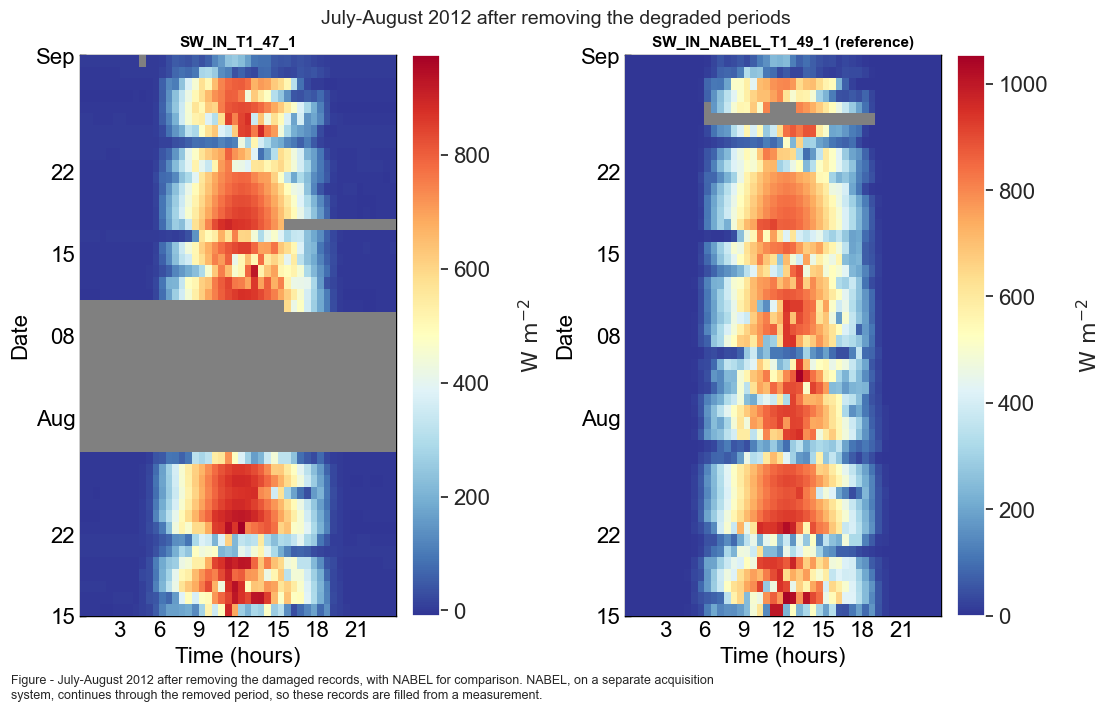

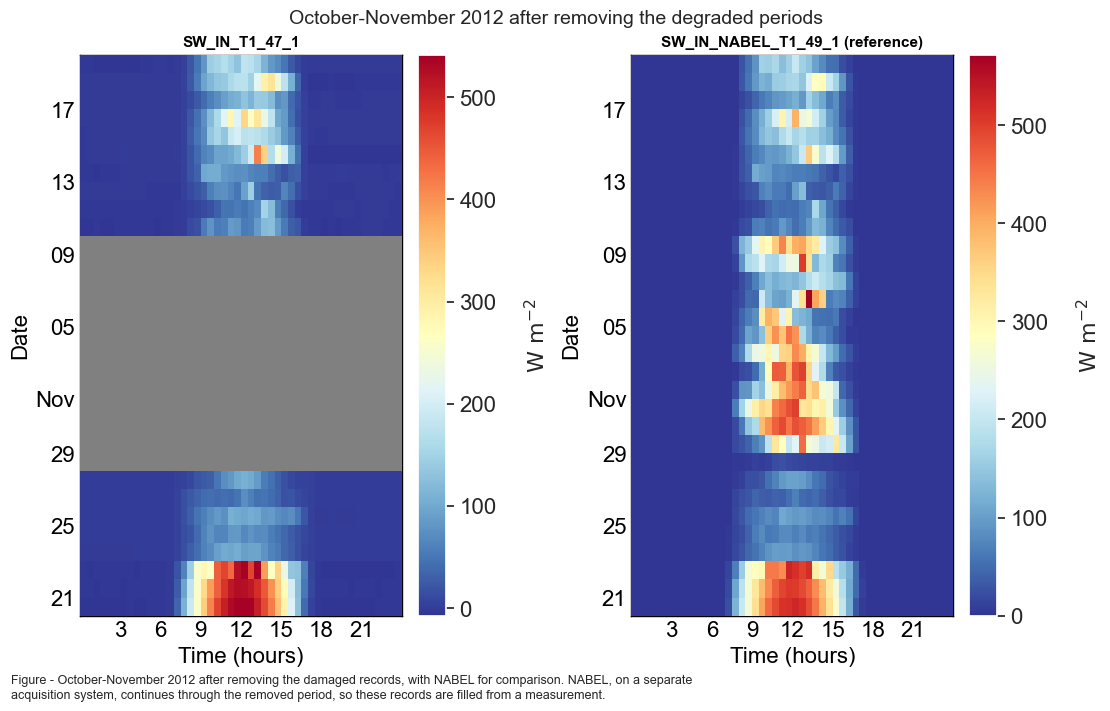

In [19]:
# Three damaged periods in 2012, all documented in the fieldbook and none repairable.
# Windows are on the CORRECTED time axis (i.e. after the +15.5 h shift above).
BAD_WINDOWS_2012 = [
    ('2012-07-29 00:00', '2012-08-10 15:30'),  # tower power supply failure (fieldbook 09.08.2012)
    ('2012-08-17 15:30', '2012-08-18 00:00'),  # transitional tail after the last shifted value
    ('2012-10-28 00:00', '2012-11-10 00:00'),  # storm damage, stressed cables (fieldbook 01./06.11.2012)
]
DEGRADED_VAR = 'SW_IN_T1_47_1'

_before = int(swin_2004_2026[DEGRADED_VAR].notna().sum())
for _start, _end in BAD_WINDOWS_2012:
    _locs = (swin_2004_2026.index >= _start) & (swin_2004_2026.index <= _end)
    swin_2004_2026.loc[_locs, DEGRADED_VAR] = np.nan
_removed = _before - int(swin_2004_2026[DEGRADED_VAR].notna().sum())
print(f"Removed {_removed} degraded records from {DEGRADED_VAR} (gap-filled later from NABEL).")

# One heatmap pair per affected period, with the NABEL sensor as the reference.
for _lo, _hi, _label in [('2012-07-15', '2012-09-01', 'July-August'),
                         ('2012-10-20', '2012-11-20', 'October-November')]:
    fig, axs = plt.subplots(ncols=2, figsize=(11, 7), dpi=100, layout="constrained")
    fig.suptitle(f'{_label} 2012 after removing the degraded periods', fontsize=14)
    _show = (swin_2004_2026.index >= _lo) & (swin_2004_2026.index <= _hi)
    dv.plotting.HeatmapDateTime(series=swin_2004_2026.loc[_show, DEGRADED_VAR]).plot(
        ax=axs[0], cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title=DEGRADED_VAR, title_fontsize=11))
    dv.plotting.HeatmapDateTime(series=swin_2004_2026.loc[_show, 'SW_IN_NABEL_T1_49_1']).plot(
        ax=axs[1], cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title='SW_IN_NABEL_T1_49_1 (reference)', title_fontsize=11))
    figcap(fig, f"{_label} 2012 after removing the damaged records, with NABEL for comparison. "
                f"NABEL, on a separate acquisition system, continues through the removed period, "
                f"so these records are filled from a measurement.")

### Nighttime zero-offset correction

A pyranometer reads a small non-zero signal at night; the `mst`-screened records carry a clearly
negative offset. The offset drifts, so it is removed per day, not as one constant. Both radiation
sensors are corrected here because the gap-filler's `correct_nighttime_offset=True` corrects only
its target, not the drivers in `context_df`.

::: {.callout-warning title="The correction writes into gaps"}
`remove_nighttime_zero_offset()` sets every nighttime position to zero, `NaN` included, so
nighttime gaps would look measured afterwards. Notebook `03` turned 7,543 modelled values into
apparent measurements this way. The gap mask is taken before the correction and restored after.
:::

#### 📋 Table: offset correction per sensor

In [20]:
# Both radiation sensors. Lägern is published offset-free (minimum exactly 0.0) and is not altered.
ZERO_OFFSET_VARS = ['SW_IN_T1_47_1', 'SW_IN_NABEL_T1_49_1']

_summary = []
NZO_BEFORE = {}   # the uncorrected series, kept so the figure below can show what was removed
NZO_RESULTS = {}  # the diagnostics object per sensor, likewise
for _var in ZERO_OFFSET_VARS:
    _series = swin_2004_2026[_var]
    NZO_BEFORE[_var] = _series.copy()

    # Capture the gap mask BEFORE correcting: the correction writes zeros into
    # nighttime NaNs and would otherwise turn gaps into apparent measurements.
    _gaps_before = _series.isna()

    _res = dv.corrections.nighttime_zero_offset_diagnostics(
        series=_series,
        lat=SITE_LAT,
        lon=SITE_LON,
        utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
    )
    NZO_RESULTS[_var] = _res

    _corrected = _res.corrected.copy()
    _corrected[_gaps_before] = np.nan  # restore the gaps the correction just filled

    # The correction must not have invented or destroyed data.
    assert _corrected.isna().equals(_gaps_before), f'{_var}: gap structure changed'

    swin_2004_2026[_var] = _corrected
    _summary.append({
        'variable': _var,
        'n_gaps': int(_gaps_before.sum()),
        'below_zero_before': _res.n_below_zero_before,
        'below_zero_before_night': _res.n_below_zero_before_night,
        'below_zero_after': int((_corrected < 0).sum()),
        'offset_min': round(float(_res.offset.min()), 3),
        'offset_max': round(float(_res.offset.max()), 3),
    })

tabcap("what the nighttime zero-offset correction removed from each sensor: negative readings "
       "before and after, and the range of the daily offset")
pd.DataFrame(_summary).set_index('variable')

Table - what the nighttime zero-offset correction removed from each sensor: negative readings before
and after, and the range of the daily offset



,n_gaps,below_zero_before,below_zero_before_night,below_zero_after,offset_min,offset_max
variable,,,,,,
SW_IN_T1_47_1,34002,133876,128454,0,-13.467,18.690
SW_IN_NABEL_T1_49_1,136058,0,0,0,0.000,0.184


#### Check: nighttime is zero and nothing is negative

Checked on measured records only; gaps are filled later.

In [21]:
# Rebuild the day/night split independently of the correction, from the site coordinates,
# so this is a real check and not a restatement of what the correction just did.
_dnf = dv.variables.DaytimeNighttimeFlag(
    timestamp_index=swin_2004_2026.index,
    nighttime_threshold=0.001,
    lat=SITE_LAT,
    lon=SITE_LON,
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
)
_is_night = _dnf.get_nighttime_flag() == 1
print(f"Nighttime records: {int(_is_night.sum()):,} of {len(swin_2004_2026):,}")

for _var in ZERO_OFFSET_VARS:
    _s = swin_2004_2026[_var]
    _measured = _s.notna()
    _night_vals = _s[_is_night & _measured]
    _n_negative = int((_s[_measured] < 0).sum())
    _n_night_nonzero = int((_night_vals != 0).sum())
    print(f"  {_var:<24s} negatives: {_n_negative:>6,}   nighttime non-zero: {_n_night_nonzero:>6,}")
    assert _n_negative == 0, f'{_var}: {_n_negative} negative values remain after correction'
    assert _n_night_nonzero == 0, f'{_var}: {_n_night_nonzero} nighttime values are not zero'

print("\nOK: no negatives, and every measured nighttime record is exactly zero.")

Nighttime records: 190,033 of 398,832
  SW_IN_T1_47_1            negatives:      0   nighttime non-zero:      0
  SW_IN_NABEL_T1_49_1      negatives:      0   nighttime non-zero:      0

OK: no negatives, and every measured nighttime record is exactly zero.


#### 📊 Plot: what the offset correction removed

Shows whether the offset drifts and how large it is next to the daytime signal.

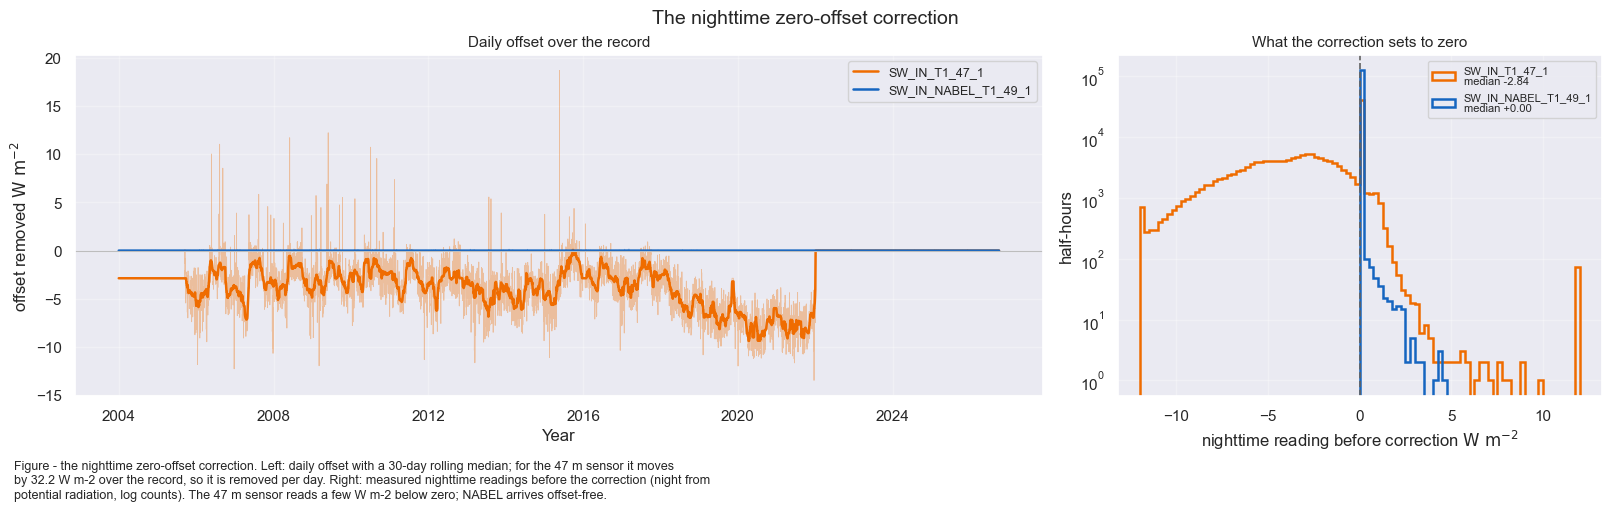

In [22]:
# The correction, drawn. Left: the daily offset over the record, per sensor. Right: the
# distribution of measured nighttime readings before the correction, which is the quantity the
# correction sets to zero.
fig, axs = plt.subplots(ncols=2, figsize=(16, 5), dpi=100, layout='constrained',
                        width_ratios=[2, 1])
fig.suptitle('The nighttime zero-offset correction', fontsize=14)

for _var, _colour in [('SW_IN_T1_47_1', '#EF6C00'), ('SW_IN_NABEL_T1_49_1', '#1565C0')]:
    _off = NZO_RESULTS[_var].offset.resample('D').mean().dropna()
    axs[0].plot(_off.index, _off, color=_colour, lw=0.6, alpha=0.35)
    axs[0].plot(_off.index, _off.rolling(30, center=True, min_periods=10).median(),
                color=_colour, lw=1.8, label=_var)
axs[0].axhline(0, color='#BDBDBD', lw=0.8)
axs[0].set_xlabel('Year')
axs[0].set_ylabel(r'offset removed $\mathrm{W\ m^{-2}}$')
axs[0].set_title('Daily offset over the record', fontsize=11)
axs[0].grid(alpha=0.3)
axs[0].legend(fontsize=9)

# Night from potential radiation, so this panel does not depend on the correction it illustrates.
_potrad_nzo = dv.variables.potrad(timestamp_index=swin_2004_2026.index, lat=SITE_LAT,
                                  lon=SITE_LON, utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
_night_nzo = _potrad_nzo <= 0
_bins = np.linspace(-12, 12, 97)
for _var, _colour in [('SW_IN_T1_47_1', '#EF6C00'), ('SW_IN_NABEL_T1_49_1', '#1565C0')]:
    _vals = NZO_BEFORE[_var][_night_nzo].dropna()
    axs[1].hist(_vals.clip(_bins[0], _bins[-1]), bins=_bins, histtype='step', lw=1.8,
                color=_colour, label=f"{_var}\nmedian {_vals.median():+.2f}")
axs[1].axvline(0, color='#616161', lw=1.2, ls='--')
axs[1].set_yscale('log')
axs[1].set_xlabel(r'nighttime reading before correction $\mathrm{W\ m^{-2}}$')
axs[1].set_ylabel('half-hours')
axs[1].set_title('What the correction sets to zero', fontsize=11)
axs[1].grid(alpha=0.3)
axs[1].legend(fontsize=8)

_span = float(NZO_RESULTS['SW_IN_T1_47_1'].offset.max() - NZO_RESULTS['SW_IN_T1_47_1'].offset.min())
figcap(fig, "the nighttime zero-offset correction. Left: daily offset with a 30-day rolling "
            f"median; for the 47 m sensor it moves by {_span:.1f} W m-2 over the record, so it "
            "is removed per day. Right: measured nighttime readings before the correction (night "
            "from potential radiation, log counts). The 47 m sensor reads a few W m-2 below "
            "zero; NABEL arrives offset-free.")

### 📋 Table: merged frame after the corrections

In [23]:
tabcap("the merged frame after the 2012 corrections and the offset removal; counts differ because the series cover different periods")
display(swin_2004_2026)
swin_2004_2026.describe()

Table - the merged frame after the 2012 corrections and the offset removal; counts differ because
the series cover different periods



,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,NaN,0.0
2004-01-01 00:45:00,NaN,0.0
2004-01-01 01:15:00,NaN,0.0
2004-01-01 01:45:00,NaN,0.0
2004-01-01 02:15:00,NaN,0.0
...,...,...
2026-09-30 21:45:00,0.0,NaN
2026-09-30 22:15:00,0.0,NaN
2026-09-30 22:45:00,0.0,NaN


,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1
count,364830.000000,262774.000000
mean,147.024025,140.035108
std,241.637475,233.702051
min,0.000000,0.000000
25%,0.000000,0.000000
50%,3.972034,2.495635
75%,199.749215,186.456335
max,1118.658439,1236.721293


***

***
## 🌍 Reference: MeteoSwiss Lägern

`SW_IN` is the position of the sun times the state of the sky. `SW_IN_POT` and the timestamp give
the first factor; only a second radiation measurement gives the second. NABEL stops in 2018.
MeteoSwiss Lägern, 2.5 km away on the same ridge at 845 m, covers the whole record, so it is a
driver in both gap-filling runs and the only one after 2018. It never overwrites a measured value.

::: {.callout-note title="Timestamp conversion"}
The reference carries `TIMESTAMP_END`. For 30MIN data the midpoint is 15 minutes earlier, so the
index is shifted back by 15 minutes. The guard below checks the alignment.
:::

### 📋 Table: tower series and the MeteoSwiss reference

In [24]:
swin_ref = pd.read_parquet(REFPATH)[[REFCOL]]
print(f"Reference read: {len(swin_ref):,} records, "
      f"{swin_ref.index[0]} -> {swin_ref.index[-1]} ({swin_ref.index.name})")

# TIMESTAMP_END -> TIMESTAMP_MID: the 30MIN bin (t-30min, t] has its midpoint at t-15min.
swin_ref.index = swin_ref.index - pd.Timedelta(minutes=15)
swin_ref.index.name = swin_2004_2026.index.name

# Guard: the shift must be right. Correlating the reference against the *measured* tower series
# at several half-hour offsets has to pick offset 0. A silently mis-shifted driver would teach
# the model the wrong sky state and there would be nothing in the output to show it.
_meas = swin_2004_2026['SW_IN_T1_47_1']
_scores = {}
for _off in (-1, 0, 1):
    _j = pd.concat([_meas.rename('t'), swin_ref[REFCOL].shift(_off).rename('r')], axis=1).dropna()
    _j = _j[_j['r'] > 20]  # daytime only: at night both are ~0 and carry no timing information
    _scores[_off] = _j['t'].corr(_j['r'])
    print(f"  offset {_off:+d} x 30min: daytime corr {_scores[_off]:.4f}")
assert max(_scores, key=_scores.get) == 0, f"reference is mis-aligned: {_scores}"
print("OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.")

swin_2004_2026 = swin_2004_2026.join(swin_ref, how='left')
print(f"\nMerged. {REFCOL} available for "
      f"{swin_2004_2026[REFCOL].notna().mean() * 100:.2f}% of records "
      f"({swin_2004_2026[REFCOL].isna().sum():,} missing)")
tabcap("the tower series and the MeteoSwiss reference; the record counts show the difference in coverage")
swin_2004_2026[['SW_IN_T1_47_1', REFCOL]].describe().round(2)

Reference read: 397,343 records, 2004-02-01 01:00:00 -> 2026-10-01 00:00:00 (TIMESTAMP_END)
  offset -1 x 30min: daytime corr 0.9296
  offset +0 x 30min: daytime corr 0.9656
  offset +1 x 30min: daytime corr 0.9079
OK: offset 0 wins, the TIMESTAMP_MID conversion is correct.

Merged. SW_IN_LAE_MS available for 99.60% of records (1,602 missing)
Table - the tower series and the MeteoSwiss reference; the record counts show the difference in
coverage



,SW_IN_T1_47_1,SW_IN_LAE_MS
count,364830.00,397230.00
mean,147.02,143.27
std,241.64,233.20
min,0.00,0.00
25%,0.00,2.00
50%,3.97,5.67
75%,199.75,193.00
max,1118.66,1155.33


#### 📊 Plot: what the two drivers offer

How closely each driver tracks the tower half-hour by half-hour, which limits how good a fill from
it can be.

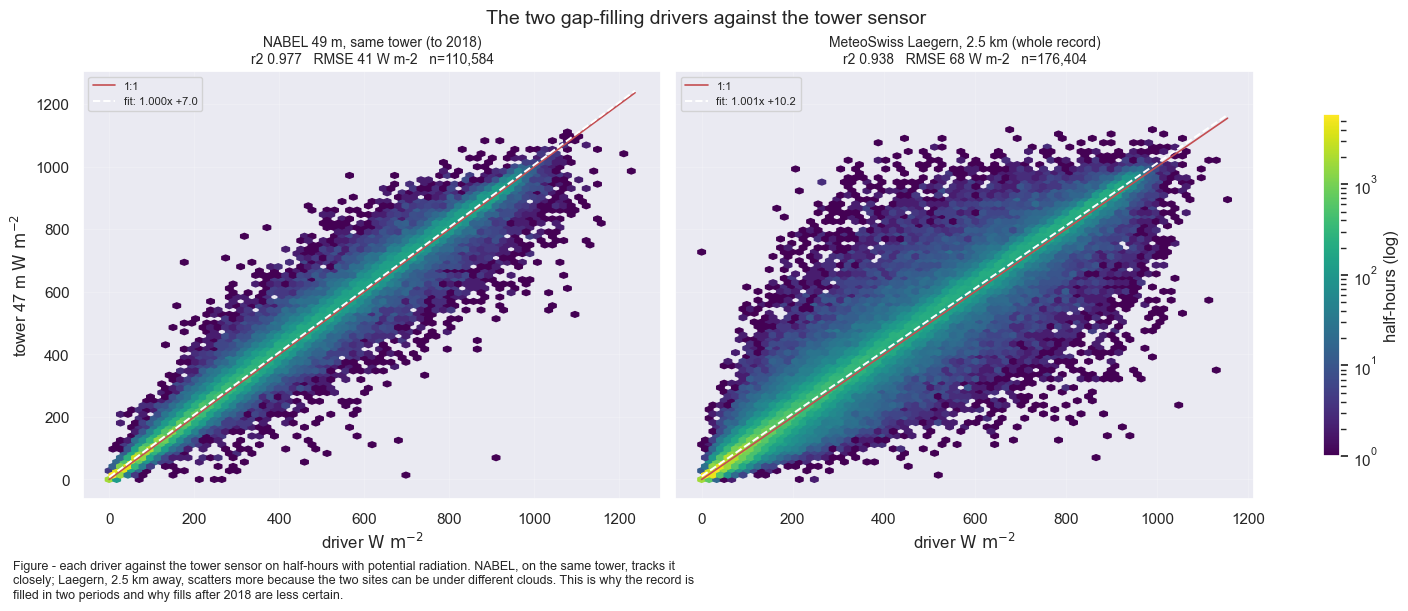

In [25]:
# Each driver against the tower sensor on well-lit half-hours. The 1:1 line and the fitted slope
# say how much of a fill's quality comes from the driver rather than from the model.
_potrad_ref = dv.variables.potrad(timestamp_index=swin_2004_2026.index, lat=SITE_LAT,
                                  lon=SITE_LON, utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
_lit_ref = _potrad_ref > 50

fig, axs = plt.subplots(ncols=2, figsize=(14, 6), dpi=100, layout='constrained', sharey=True)
fig.suptitle('The two gap-filling drivers against the tower sensor', fontsize=14)

for _ax, _driver, _label in [
        (axs[0], 'SW_IN_NABEL_T1_49_1', 'NABEL 49 m, same tower (to 2018)'),
        (axs[1], REFCOL, 'MeteoSwiss Laegern, 2.5 km (whole record)')]:
    _j = swin_2004_2026.loc[_lit_ref, ['SW_IN_T1_47_1', _driver]].dropna()
    _hb = _ax.hexbin(_j[_driver], _j['SW_IN_T1_47_1'], gridsize=70, mincnt=1, bins='log',
                     cmap='viridis')
    _lim = [0, float(max(_j.max()))]
    _ax.plot(_lim, _lim, 'r-', lw=1.2, label='1:1')
    _slope, _icpt = np.polyfit(_j[_driver].to_numpy(), _j['SW_IN_T1_47_1'].to_numpy(), 1)
    _ax.plot(_lim, [_slope * _x + _icpt for _x in _lim], color='w', lw=1.4, ls='--',
             label=f'fit: {_slope:.3f}x {_icpt:+.1f}')
    _r2 = _j[_driver].corr(_j['SW_IN_T1_47_1']) ** 2
    _rmse = float(np.sqrt(((_j['SW_IN_T1_47_1'] - _j[_driver]) ** 2).mean()))
    _ax.set_title(f"{_label}\nr2 {_r2:.3f}   RMSE {_rmse:.0f} W m-2   n={len(_j):,}", fontsize=10)
    _ax.set_xlabel(r'driver $\mathrm{W\ m^{-2}}$')
    _ax.legend(fontsize=8, loc='upper left')
    _ax.grid(alpha=0.2)
axs[0].set_ylabel(r'tower 47 m $\mathrm{W\ m^{-2}}$')
fig.colorbar(_hb, ax=axs, label='half-hours (log)', shrink=0.8)

figcap(fig, "each driver against the tower sensor on half-hours with potential radiation. "
            "NABEL, on the same tower, tracks it closely; Laegern, 2.5 km away, scatters more "
            "because the two sites can be under different clouds. This is why the record is "
            "filled in two periods and why fills after 2018 are less certain.")

***

## 🔎 The 2016 acquisition change and the two references

The tower logger was replaced on 21 January 2016, and `TA_T1_47_1` steps by about 1.3 °C there
(notebook `02`). `SW_IN_T1_47_1` runs on the same acquisition system and **does not step**. The
same scan over the whole record finds:

1. the sensor and its calibration did not change in 2016: every logger program applies the same
   conversion to the same instrument;
2. the data show no step at the changeover, judged against the event threshold and the record's
   own worst year;
3. the NABEL sensor is a second instrument, so it is an independent driver and a valid reference
   for the 2012 correction;
4. MeteoSwiss Lägern stepped by about 5 % in October 2010, at the reference station, not the
   tower;
5. the radiometer was replaced in December 2021 (CNR1 to CNR4), and the series did not step there
   either;
6. the tower sensor departs from both references by about 3 % from 2013, with no documented cause.
   It is stated, not corrected.

The full four-sensor attribution is in `RADIATION_SENSOR_CONTINUITY.ipynb`.

### Helpers for this section

The logger programs and the fieldbook are read in the notebook, not quoted. Both name people and
this notebook is published, so every string taken from them is redacted, as in notebooks `02` and
`08`.

In [26]:

# --- Fieldbook and logger-script redaction ----------------------------------------------------
# The GIN export and the logger programs both name people. This notebook renders to a public page,
# so every string taken out of either passes through redact_people() at the single point where it
# is flattened. Same map and same rules as notebooks 02 and 08; the map lives beside the export,
# OUTSIDE this repository, so the repo never carries a real name.
REDACT_MAP = Path(FIELDBOOK).with_name('redact_names.csv')
ALLOW_LIST = Path(FIELDBOOK).with_name('redact_allow.csv')


def unmapped_report_path(label: str) -> Path:
    """Where the unmapped-name candidates of one audit are written.

    Per label, because this notebook audits two sources: a single shared file would let the
    second audit overwrite the first one's findings.
    """
    _slug = re.sub(r'[^a-z0-9]+', '_', label.lower()).strip('_')
    return Path(FIELDBOOK).with_name(f'redact_unmapped_{_slug}.txt')


def load_redactions(path=None) -> dict:
    """Load the name -> pseudonym map.

    Raises if the map is missing. That is the point: carrying on with redaction quietly disabled
    prints real names into a published page and looks exactly like success.
    """
    path = REDACT_MAP if path is None else Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"the redaction map is missing: {path}. Without it the names these files record would "
            f"print unredacted. Restore the file rather than skipping this.")
    tab = pd.read_csv(path, encoding='utf-8')
    missing = {'name', 'pseudonym'}.difference(tab.columns)
    if missing:
        raise ValueError(f"{path}: missing column(s) {sorted(missing)}.")
    pairs = {str(n).strip(): str(p).strip()
             for n, p in zip(tab['name'], tab['pseudonym']) if str(n).strip()}
    if not pairs:
        raise ValueError(f"{path}: holds no usable name -> pseudonym pairs.")
    return pairs


REDACTIONS = load_redactions()
# Longest surface form first, so a bare surname cannot corrupt a double-barrelled one that starts
# with it. Lookarounds rather than \b, because some forms end in an initial.
_REDACT_RX = re.compile(r'(?<!\w)(' + '|'.join(re.escape(n) for n in
                                               sorted(REDACTIONS, key=len, reverse=True))
                        + r')(?!\w)')


def redact_people(s) -> str:
    """Replace every mapped name with its stable pseudonym."""
    return _REDACT_RX.sub(lambda m: REDACTIONS[m.group(1)], str(s))


def strip_html(text) -> str:
    """Flatten one GIN fieldbook entry to plain text, with the people it names redacted."""
    flat = html.unescape(re.sub(r'<[^>]+>', ' ', str(text)))
    return redact_people(re.sub(r'\s+', ' ', flat).strip())


_NAME_TOKEN = r"[A-ZÄÖÜ][\wÄÖÜäöüß'-]{1,20}"
_NAME_UNIT = _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r'){0,2}'
_NAME_SHAPES = (
    re.compile(r'\((' + _NAME_UNIT + r'(?:\s*[,+&]\s*' + _NAME_UNIT + r')*)\s*'
               r'(?:\d{1,2}\.\d{1,2}\.\d{4})?\)'),
    re.compile(r'(?:with|by|durch|von|gemaess)\s+(' + _NAME_TOKEN + r'(?:\s+' + _NAME_TOKEN + r')?)'),
)


def audit_unmapped_names(texts, label='fieldbook', write_report: bool = True) -> int:
    """Raise if any name-shaped token survived redaction.

    A newer export can name someone the map has never seen. Candidates are never printed - an
    exception message is stored in a notebook like any other output - so they go to a file beside
    the map and only the count is shown.
    """
    allow = set(pd.read_csv(ALLOW_LIST, encoding='utf-8')['term'].astype(str).str.strip())
    found = {}
    for _t in texts:
        for _rx in _NAME_SHAPES:
            for _m in _rx.finditer(str(_t)):
                for _tok in re.findall(_NAME_TOKEN, _m.group(1)):
                    if _tok.isupper() or any(ch.isdigit() for ch in _tok) or _tok in allow:
                        continue
                    found[_tok] = found.get(_tok, 0) + 1
    if found:
        _report = unmapped_report_path(label)
        if write_report:
            _report.write_text(
                '\n'.join(f'{n}\t{t}' for t, n in sorted(found.items(), key=lambda kv: -kv[1])),
                encoding='utf-8')
        raise ValueError(
            f"{label}: {len(found)} name-shaped token(s) survived redaction. They are deliberately "
            f"NOT shown here - see {_report}. Add the people to redact_names.csv and the "
            f"technical terms to redact_allow.csv, then re-run.")
    print(f"  {label}: no unmapped name-shaped tokens ({len(allow)} allowlisted terms)")
    return 0


def program_excerpt(path, pattern: str, before: int = 6, after: int = 4, expect: int = 1) -> str:
    """The lines of a logger program around `pattern`, redacted.

    Only the matched instruction is returned, never the file header: these programs are signed by
    their authors. Raises unless the pattern matches exactly `expect` times. Both directions
    matter: no match reads as 'the program does not measure this', and an over-broad pattern
    quietly prints the wrong instruction next to the argument it is supposed to support.
    """
    lines = Path(path).read_text(encoding='latin-1').splitlines()
    blocks = []
    for i, line in enumerate(lines):
        if re.search(pattern, line):
            lo, hi = max(0, i - before), min(len(lines), i + after + 1)
            blocks.append('\n'.join(lines[lo:hi]))
    if len(blocks) != expect:
        raise ValueError(f"{Path(path).name}: {pattern!r} matched {len(blocks)} time(s), expected "
                         f"{expect}. The program layout has changed, the wrong file is configured, "
                         f"or the pattern is not specific enough.")
    return redact_people('\n\n'.join(blocks))


def calibration_constants(excerpt: str) -> dict:
    """The multiplier and offset of one measurement instruction, parsed from its own text.

    The two program languages write the same two numbers differently - the CR10X lists them as
    numbered parameters, the CR1000 as positional arguments - so each is matched on its own shape
    and the result compared. Raises if either number cannot be found, because a silently empty
    dict would make the comparison below pass by having nothing to disagree about.
    """
    if 'Mult' in excerpt:                                    # CR10X parameter listing
        mult = re.search(r'^\s*\d+:\s*([\d.]+)\s+Mult', excerpt, re.M)
        offset = re.search(r'^\s*\d+:\s*([\d.]+)\s+Offset', excerpt, re.M)
    else:                                                    # CR1000 VoltDiff(...) call
        call = re.search(r'VoltDiff\s*\(([^)]*)\)', excerpt)
        args = [a.strip() for a in call.group(1).split(',')] if call else []
        mult = re.match(r'([\d.]+)$', args[-2]) if len(args) >= 2 else None
        offset = re.match(r'([\d.]+)$', args[-1]) if len(args) >= 2 else None
    if not (mult and offset):
        raise ValueError("could not parse a multiplier and an offset from the instruction - the "
                         "program language or the layout has changed")
    return {'multiplier': float(mult.group(1)), 'offset': float(offset.group(1))}


In [27]:

# The guards guard. A helper that silently returns nothing is worse than no helper, so every
# failure path is exercised before anything is read.
try:
    program_excerpt(PROGRAM_AFTER, r'ThisPatternIsNotInAnyLoggerProgram')
except ValueError as _exc:
    print(f"OK, program_excerpt raised on a pattern that does not occur: {_exc}")
else:
    raise AssertionError("(!) program_excerpt accepted a pattern that does not occur.")

# 'Ada Lovelace' is nobody at this site, so the control can spell her out without disclosing
# anything - and it writes no report, so the real one is not overwritten by a test.
try:
    audit_unmapped_names(['12.05.2019 (Ada Lovelace) replaced the logger battery'],
                         'positive control', write_report=False)
except ValueError:
    print("OK, the unknown-name net fired on a name that is not in the map")
else:
    raise AssertionError("(!) the unknown-name net did not fire on an unmapped name.")

# And the constant parser must refuse an instruction it cannot read, rather than return an empty
# comparison that would agree with anything.
try:
    calibration_constants("18:  Volt (Diff) (P2) ;Messung von Kin\n 1: 1        Reps")
except ValueError as _exc:
    print(f"OK, calibration_constants raised on an instruction with no constants: {_exc}")
else:
    raise AssertionError("(!) calibration_constants accepted an instruction carrying no constants.")


OK, program_excerpt raised on a pattern that does not occur: CH-LAE_iDL_T1_47_1.CR1: 'ThisPatternIsNotInAnyLoggerProgram' matched 0 time(s), expected 1. The program layout has changed, the wrong file is configured, or the pattern is not specific enough.
OK, the unknown-name net fired on a name that is not in the map
OK, calibration_constants raised on an instruction with no constants: could not parse a multiplier and an offset from the instruction - the program language or the layout has changed


### 1️⃣ The sensor and its calibration did not change

`TA` stepped in 2016 because sensor and conversion changed together: a Rotronic MP101A read as an
analog voltage at `Mult 0.1` became a Campbell CS215 read over SDI-12 at multiplier `1`. For
shortwave radiation the programs show no change. The two constants are parsed from every program
on each run.

#### 📋 Table: calibration constants per logger program

In [28]:

# Every logger program on disk that measures this sensor, read rather than quoted. The CR10X
# programs are listed oldest first; the CR1000 program is the one installed at the changeover.
CONSTANTS = {}

print("=" * 78)
print("BEFORE 2016: the CR10X programs")
print("=" * 78)
_cr10x_excerpts = []
for _p in PROGRAMS_BEFORE:
    _ex = program_excerpt(_p, r'Messung von Kin', before=5, after=6)
    _cr10x_excerpts.append(_ex)
    CONSTANTS[Path(_p).name] = calibration_constants(_ex)
    print(f"\n--- {Path(_p).name}")
    print(_ex)

print("\n" + "=" * 78)
print(f"AFTER 2016:  {Path(PROGRAM_AFTER).name}")
print("=" * 78)
_cr1000_excerpt = program_excerpt(PROGRAM_AFTER, r'VoltDiff\(SW_IN_T1_47_1', before=5, after=0)
CONSTANTS[Path(PROGRAM_AFTER).name] = calibration_constants(_cr1000_excerpt)
print(_cr1000_excerpt)

# These files are signed by their authors, so they get the same two nets as the fieldbook:
# redaction inside program_excerpt, and the unknown-name audit here.
audit_unmapped_names(_cr10x_excerpts + [_cr1000_excerpt], 'logger programs')

tabcap("the conversion each logger program applies to this sensor's voltage; the 2016 "
       "changeover changed neither constant")
_const = pd.DataFrame(CONSTANTS).T
_const.index.name = 'logger program'
display(_const)

# The decisive assertion of this step. If the multiplier had changed, SW_IN would step at the
# changeover by construction and the rest of this section would be measuring that.
_mults = {v['multiplier'] for v in CONSTANTS.values()}
_offsets = {v['offset'] for v in CONSTANTS.values()}
print(f"\ndistinct multipliers across all {len(CONSTANTS)} programs: {sorted(_mults)}")
print(f"distinct offsets:    {sorted(_offsets)}")
print(f"implied sensitivity: {1000 / max(_mults):.2f} uV/W/m2 "
      f"(the CNR1 calibration factor named in the programs' own comments)")
assert len(_mults) == 1 and len(_offsets) == 1, (
    "the logger programs do not all apply the same conversion to SW_IN - the argument that the "
    "2016 changeover cannot have moved this series no longer holds")
assert _offsets == {0.0}, "a non-zero offset appeared in a program - re-derive the argument below"


BEFORE 2016: the CR10X programs

--- LAEGEREN.20050818.CSI
;-----------------------------------------------------------------------
; Net Radiometer CNR1 from NABEL-Station,sn: 020484, factor=10.03uV/W/m2
;-----------------------------------------------------------------------


18:  Volt (Diff) (P2) ;Messung von Kin
 1: 1        Reps
 2: 33       25 mV 50 Hz Rejection Range
 3: 3        DIFF Channel
 4: 23       Loc [ Kin       ]
 5: 99.7009  Mult
 6: 0.0      Offset

--- LAEGEREN.20050914.CSI
;-----------------------------------------------------------------------
; Net Radiometer CNR1 from NABEL-Station,sn: 020484, factor=10.03uV/W/m2
;-----------------------------------------------------------------------


18:  Volt (Diff) (P2) ;Messung von Kin
 1: 1        Reps
 2: 33       25 mV 50 Hz Rejection Range
 3: 3        DIFF Channel
 4: 23       Loc [ Kin       ]
 5: 99.7009  Mult
 6: 0.0      Offset

--- LAEGEREN.20060524.csi
;----------------------------------------------------------

,multiplier,offset
logger program,,
LAEGEREN.20050818.CSI,99.7009,0.0
LAEGEREN.20050914.CSI,99.7009,0.0
LAEGEREN.20060524.csi,99.7009,0.0
CH-LAE_iDL_T1_47_1.CR1,99.7009,0.0



distinct multipliers across all 4 programs: [99.7009]
distinct offsets:    [0.0]
implied sensitivity: 10.03 uV/W/m2 (the CNR1 calibration factor named in the programs' own comments)


Both systems measure **the same instrument with the same calibration**: a Kipp & Zonen CNR1, SN
020484, on a 25 mV differential channel at multiplier `99.7009` and offset `0`. The multiplier is
`1000 / 10.03`, the sensitivity in the programs' comments. The logger change altered how the
voltage was digitised, not what it meant.

::: {.callout-note title="Coverage of the programs"}
Three CR10X programs cover August 2005 to May 2006; the CR1000 program dates from January 2016.
**No tower program from May 2006 to January 2016 survives**, so the constants could have changed
and changed back in that gap. The programs fix the two endpoints; the data below cover the
interval and show no change.
:::

The 2004 programs measure no incoming shortwave; their comments say the radiometer channels
carried a PAR sensor. The CNR1 instruction first appears in the program of **18 August 2005**. The
tower record begins 27 days later, on 14 September 2005, the date of the next program, which moves
the outgoing channels onto DIFF3 and DIFF4. The assertion below allows for this month.

In [29]:

# A second, independent date from the same programs. The three CR10X programs of 2004 measure no
# incoming shortwave at all - their comments record that the radiometer's channels carried a PAR
# sensor "in earlier times" - and the CNR1 measurement first appears in the program dated
# 18 August 2005. The record begins 27 days later, on 14 September 2005, the date of the next
# program. The tolerance below is a month because of that gap, not because the date is vague.
RECORD_START = swin_2004_2026['SW_IN_T1_47_1'].dropna().index[0]
_first_prog = min(re.search(r'\.(\d{8})\.', Path(p).name).group(1) for p in PROGRAMS_BEFORE)
_first_prog = pd.Timestamp(_first_prog)
print(f"earliest program carrying the CNR1 measurement: {_first_prog:%d %b %Y}")
print(f"first measured SW_IN_T1_47_1 record:            {RECORD_START:%d %b %Y %H:%M}")
print(f"difference: {(RECORD_START.normalize() - _first_prog).days} day(s)")
assert abs((RECORD_START.normalize() - _first_prog).days) <= 31, (
    "the record does not begin when the sensor was first programmed - one of the two has moved "
    "and the identification of the instrument needs re-checking")


earliest program carrying the CNR1 measurement: 18 Aug 2005
first measured SW_IN_T1_47_1 record:            14 Sep 2005 11:15
difference: 27 day(s)


### 2️⃣ Reading the three sensors against each other

A radiometer error is **multiplicative**, so every comparison is a ratio and a level change is a
percentage. The helper has two controls built in:

- **Season.** Medians are taken per calendar month and averaged over months, restricted to
  April-September, where snow and rime on the sensor cannot act.
- **Illumination.** Only half-hours with *potential* radiation above 300 W m⁻² enter, and both
  series must exceed 50 W m⁻². Potential radiation is astronomical, so it cannot drift. At low sun
  the ratio reflects horizons and sensor levelling, not calibration.

In [30]:

# Radiation errors are multiplicative, so every comparison is a ratio. Controls: see above.
WELL_LIT = 300.0        # W m-2 of POTENTIAL radiation: astronomical, so it cannot drift
MIN_IRRADIANCE = 50.0   # W m-2 measured, at both stations
SUMMER_MONTHS = [4, 5, 6, 7, 8, 9]

POTRAD = dv.variables.potrad(timestamp_index=swin_2004_2026.index,
                             lat=SITE_LAT, lon=SITE_LON,
                             utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)


def ratio_by_year(num: str, den: str, summer_only: bool = True, min_records: int = 100):
    """Month-matched yearly median of `num`/`den` over well-lit half-hours.

    `summer_only` restricts to April-September. Snow and rime on an upward-facing sensor, and the
    large horizon differences at low sun, both act in winter and both would be read as a
    calibration change; the summer window removes them. The unrestricted version is available so
    that a result can be shown not to depend on the choice.
    """
    _mask = POTRAD > WELL_LIT
    if summer_only:
        _mask = _mask & swin_2004_2026.index.month.isin(SUMMER_MONTHS)
    _j = swin_2004_2026.loc[_mask, [num, den]].dropna()
    _j = _j[(_j[num] > MIN_IRRADIANCE) & (_j[den] > MIN_IRRADIANCE)]
    if len(_j) < min_records * 12:
        raise ValueError(f"{num}/{den}: only {len(_j)} usable half-hours, too few to build "
                         f"monthly medians from")
    _r = _j[num] / _j[den]
    _m = _r.groupby([_r.index.year, _r.index.month]).median()
    _m.index.names = ['year', 'month']
    _n = _r.groupby([_r.index.year, _r.index.month]).count()
    _m = _m[_n >= min_records]
    if _m.empty:
        raise ValueError(f"{num}/{den}: no calendar month reaches {min_records} records")
    return _m.groupby(level=0).mean()


def step_at(series: pd.Series, year: int, span: int = 3) -> float:
    """Percentage change of a yearly ratio across `year`, over `span` years either side.

    The candidate year itself is excluded from both sides: a change that happens inside a year
    belongs to neither era, and including it would halve the step it is meant to measure.
    """
    _pre = series.reindex(range(year - span, year)).dropna()
    _post = series.reindex(range(year + 1, year + 1 + span)).dropna()
    if len(_pre) < 2 or len(_post) < 2:
        return float('nan')
    return 100 * (_post.mean() / _pre.mean() - 1)


In [31]:

# The guards guard, again. Both helpers would otherwise return a plausible number from almost no
# data: ratio_by_year on a window holding a handful of half-hours, step_at on a year the record
# does not reach. ratio_by_year has two separate guards - too little data overall, and enough
# overall but no single month populated - so both are exercised, because a control that only ever
# trips the first would leave the second untested.
for _thresh, _which in [(100_000, 'too few half-hours in total'),
                        (4_000, 'enough in total, but no single calendar month')]:
    try:
        ratio_by_year('SW_IN_T1_47_1', 'SW_IN_NABEL_T1_49_1', min_records=_thresh)
    except ValueError as _exc:
        print(f"OK, ratio_by_year raised on '{_which}': {_exc}")
    else:
        raise AssertionError(f"(!) ratio_by_year accepted a threshold no data can meet ({_which}).")

_probe = ratio_by_year('SW_IN_T1_47_1', REFCOL)
assert np.isnan(step_at(_probe, 1990)), "(!) step_at returned a number for a year off the record"
print("OK, step_at returns nan for a year the record does not cover")


OK, ratio_by_year raised on 'too few half-hours in total': SW_IN_T1_47_1/SW_IN_NABEL_T1_49_1: only 51498 usable half-hours, too few to build monthly medians from
OK, ratio_by_year raised on 'enough in total, but no single calendar month': SW_IN_T1_47_1/SW_IN_NABEL_T1_49_1: no calendar month reaches 4000 records
OK, step_at returns nan for a year the record does not cover


### 3️⃣ The data show no step at the changeover

Three sensors give three pairwise ratios. A calibration change at one sensor moves every ratio it
appears in and no other. The change across 2016 is measured the same way as across every other
year, so it is judged against the record's own variability.

#### 📋 Table: pairwise ratios by year

In [32]:

# Every pairwise ratio among the three sensors, by year. 2016 is judged against the other years.
PAIRS = [('tower 47 m / MeteoSwiss', 'SW_IN_T1_47_1', REFCOL),
         ('tower 47 m / NABEL 49 m', 'SW_IN_T1_47_1', 'SW_IN_NABEL_T1_49_1'),
         ('NABEL 49 m / MeteoSwiss', 'SW_IN_NABEL_T1_49_1', REFCOL)]
RATIOS = {_label: ratio_by_year(_a, _b) for _label, _a, _b in PAIRS}
ratio_table = pd.DataFrame(RATIOS)
ratio_table.index.name = 'YEAR'

tabcap("each pairwise ratio by year, in % of its 2006-2010 mean")
_base = ratio_table.loc[2006:2010].mean()
display((100 * (ratio_table / _base - 1)).round(2))

BREAK_YEAR = 2016

Table - each pairwise ratio by year, in % of its 2006-2010 mean



,tower 47 m / MeteoSwiss,tower 47 m / NABEL 49 m,NABEL 49 m / MeteoSwiss
YEAR,,,
2004,NaN,NaN,-1.68
2005,1.57,4.49,-2.25
2006,-0.35,0.52,-0.94
2007,-0.43,-0.20,-0.18
2008,-0.69,-0.08,-0.70
2009,0.15,-0.32,0.59
2010,1.31,0.08,1.23
2011,-5.50,-0.58,-5.08
2012,-4.41,-0.56,-4.33


#### 📋 Table: change across 2016

In [33]:
tabcap(f"the change across {BREAK_YEAR} in each ratio, against the largest change elsewhere "
       f"in the record")
_rows = []
for _label in RATIOS:
    _s = RATIOS[_label]
    _elsewhere = {_y: step_at(_s, _y) for _y in _s.index if _y != BREAK_YEAR}
    _elsewhere = pd.Series(_elsewhere).dropna()
    _rows.append({'pair': _label,
                  f'change across {BREAK_YEAR} (%)': step_at(_s, BREAK_YEAR),
                  'median |change| elsewhere (%)': _elsewhere.abs().median(),
                  'largest |change| elsewhere (%)': _elsewhere.abs().max(),
                  'year of that largest change': int(_elsewhere.abs().idxmax())})
break_table = pd.DataFrame(_rows).set_index('pair')
break_table['year of that largest change'] = break_table['year of that largest change'].astype(int)
display(break_table.round(2))

# Assert on the two pairs that contain the tower sensor only. The 2016 changeover replaced this
# tower's logger and cannot have moved either reference.
TOWER_PAIRS = [_l for _l in RATIOS if _l.startswith('tower')]
assert len(TOWER_PAIRS) == 2, "the pair list has changed - re-check which pairs the assertion covers"

# Event threshold, as in RADIATION_SENSOR_CONTINUITY.ipynb: above the ordinary-year variability
# (about 1 %) and well under half the October 2010 step at the reference station.
EVENT_THRESHOLD = 2.0
assert EVENT_THRESHOLD > break_table['median |change| elsewhere (%)'].max(), (
    "the threshold has fallen below the median change this measurement finds in an ordinary "
    "year, which would make it fire on nothing having happened")

# The change across 2016 must be below the threshold AND below the worst change elsewhere. If a
# re-run breaks either, the series has moved: re-derive this section, do not relax it.
for _label in TOWER_PAIRS:
    _row = break_table.loc[_label]
    _change = _row[f'change across {BREAK_YEAR} (%)']
    print(f"  {_label}: {_change:+.2f} % across {BREAK_YEAR}, against "
          f"{_row['median |change| elsewhere (%)']:.2f} % in a typical year and "
          f"{_row['largest |change| elsewhere (%)']:.2f} % at its worst "
          f"({int(_row['year of that largest change'])})")
    assert abs(_change) < EVENT_THRESHOLD, (
        f"{_label} changes by {_change:.2f} % across {BREAK_YEAR}, past the {EVENT_THRESHOLD} % "
        f"an event is counted at - SW_IN may have moved at the acquisition change after all, and "
        f"this section must be re-derived")
    assert abs(_change) < _row['largest |change| elsewhere (%)'], (
        f"{_label}: the change across {BREAK_YEAR} is now the largest in the record, which is the "
        f"opposite of what this section concludes")
print(f"\nBoth pairs involving the tower sensor change by less than {EVENT_THRESHOLD} % across "
      f"{BREAK_YEAR}, and by less than they change at their worst elsewhere in the record.")


Table - the change across 2016 in each ratio, against the largest change elsewhere in the record



,change across 2016 (%),median |change| elsewhere (%),largest |change| elsewhere (%),year of that largest change
pair,,,,
tower 47 m / MeteoSwiss,-0.27,0.63,3.63,2010
tower 47 m / NABEL 49 m,-0.99,1.84,2.90,2013
NABEL 49 m / MeteoSwiss,1.35,1.98,4.91,2011


  tower 47 m / MeteoSwiss: -0.27 % across 2016, against 0.63 % in a typical year and 3.63 % at its worst (2010)
  tower 47 m / NABEL 49 m: -0.99 % across 2016, against 1.84 % in a typical year and 2.90 % at its worst (2013)

Both pairs involving the tower sensor change by less than 2.0 % across 2016, and by less than they change at their worst elsewhere in the record.


### 4️⃣ The NABEL sensor is a second instrument

Both logger programs call the 47 m sensor *"Net Radiometer CNR1 from NABEL-Station"*. If
`SW_IN_NABEL_T1_49_1` were the same instrument on a second acquisition system, it would check
nothing: not as a driver for 2004-2018, and not as the reference the 2012 timestamp correction was
dated against. It is a different instrument: the 47 m CNR1 belongs to NABEL and is read by this
tower's logger, while NABEL's own sensor sits at 49 m on its own system.

#### 📋 Table: how closely each reference tracks the tower

In [34]:

# Is SW_IN_NABEL_T1_49_1 a second instrument, or the same one recorded twice? The programs above
# describe the sensor at 47 m as the NABEL station's own CNR1, which leaves the question open, and
# it matters: a driver that is secretly the target teaches the gap-filler nothing, and the 2012
# timestamp correction above was dated against this series.
_both = swin_2004_2026[['SW_IN_T1_47_1', 'SW_IN_NABEL_T1_49_1']].dropna()
_both = _both[(POTRAD.reindex(_both.index) > WELL_LIT)]
_d = _both['SW_IN_T1_47_1'] - _both['SW_IN_NABEL_T1_49_1']

# The same statistics against MeteoSwiss, which is certainly a different instrument at a different
# place, so the numbers above have something to be read against.
_bm = swin_2004_2026[['SW_IN_T1_47_1', REFCOL]].dropna()
_bm = _bm[(POTRAD.reindex(_bm.index) > WELL_LIT)]
_dm = _bm['SW_IN_T1_47_1'] - _bm[REFCOL]

tabcap("how closely each reference tracks the tower sensor on well-lit half-hours; two "
       "digitisations of one instrument would agree to within rounding")
display(pd.DataFrame({
    'NABEL 49 m': {'half-hours compared': len(_both),
                   'correlation': _both.corr().iloc[0, 1],
                   'SD of difference (W m-2)': _d.std(),
                   'agree within 1 W m-2 (%)': 100 * (_d.abs() < 1).mean(),
                   'agree within 5 W m-2 (%)': 100 * (_d.abs() < 5).mean()},
    'MeteoSwiss Laegern': {'half-hours compared': len(_bm),
                           'correlation': _bm.corr().iloc[0, 1],
                           'SD of difference (W m-2)': _dm.std(),
                           'agree within 1 W m-2 (%)': 100 * (_dm.abs() < 1).mean(),
                           'agree within 5 W m-2 (%)': 100 * (_dm.abs() < 5).mean()},
}).round(3))

# The second, independent argument: for more than a year NABEL measures while the tower does not.
# One instrument cannot do that.
_only_nabel = int((swin_2004_2026['SW_IN_NABEL_T1_49_1'].notna()
                   & swin_2004_2026['SW_IN_T1_47_1'].isna()
                   & (POTRAD > WELL_LIT) & (swin_2004_2026.index < RECORD_START)).sum())
print(f"\nwell-lit half-hours measured by NABEL before the tower record begins: {_only_nabel:,}")
print(f"  (the CNR1 was wired to the tower logger on {RECORD_START:%d %b %Y}; NABEL was already "
      f"recording)")

assert 100 * (_d.abs() < 1).mean() < 25, (
    "the tower and NABEL series now agree like two copies of one measurement - if they are the "
    "same instrument, NABEL is not an independent driver and the 2012 correction above rests on "
    "a sensor compared against itself")
assert _only_nabel > 1000, (
    "NABEL no longer covers well-lit half-hours the tower does not - the second argument for two "
    "instruments has gone")
print("Two instruments, on two acquisition systems. NABEL is an independent reference here.")


Table - how closely each reference tracks the tower sensor on well-lit half-hours; two digitisations
of one instrument would agree to within rounding



,NABEL 49 m,MeteoSwiss Laegern
half-hours compared,88308.000,141093.000
correlation,0.985,0.960
SD of difference (W m-2),44.973,74.722
agree within 1 W m-2 (%),8.512,2.773
agree within 5 W m-2 (%),27.595,13.737



well-lit half-hours measured by NABEL before the tower record begins: 11,999
  (the CNR1 was wired to the tower logger on 14 Sep 2005; NABEL was already recording)
Two instruments, on two acquisition systems. NABEL is an independent reference here.


### 5️⃣ MeteoSwiss Lägern moved in October 2010; the tower did not

The same scan over every year finds a change several times larger than anything at 2016, at the
reference station.

#### 📋 Table: change at every year of the record

In [35]:

# The reference station itself. The scan above is repeated over the whole record rather than at
# one candidate year, so the largest change anywhere is found blind and then attributed.
_scan = pd.DataFrame({_label: {_y: step_at(_s, _y) for _y in _s.index}
                      for _label, _s in RATIOS.items()}).sort_index()
_scan.index.name = 'YEAR'
tabcap("the change (three years either side) at every year of the record. The largest "
       "entries of both MeteoSwiss columns fall on the same year; the third column is quiet there")
display(_scan.round(2))

MS_STEP_YEAR = int(_scan['tower 47 m / MeteoSwiss'].abs().idxmax())
print(f"\nlargest change in tower / MeteoSwiss anywhere in the record: {MS_STEP_YEAR}")
for _label in RATIOS:
    print(f"  {_label}: {_scan.loc[MS_STEP_YEAR, _label]:+.2f} %")

# When the reference station's own instrumentation changed, read off the reference file rather
# than asserted: diffuse radiation is a channel MeteoSwiss Laegern did not have before.
_diffuse_start = pd.read_parquet(REFPATH)['SW_IN_DIFF_LAE_MS'].dropna().index[0]
print(f"\nMeteoSwiss Laegern first reports diffuse radiation on {_diffuse_start:%d %b %Y %H:%M}, "
      f"a channel that needs a shading device the station did not previously carry.")

# Both references move together against the tower, and the tower does not move against NABEL.
# That is what puts the change at MeteoSwiss rather than here.
assert _scan.loc[MS_STEP_YEAR, 'NABEL 49 m / MeteoSwiss'] < -2.0, (
    "NABEL no longer steps against MeteoSwiss in the same year as the tower does - the change can "
    "no longer be attributed to the reference station")
assert abs(_scan.loc[MS_STEP_YEAR, 'tower 47 m / NABEL 49 m']) < 1.0, (
    "the tower now steps against NABEL in that year too - the change is not confined to the "
    "reference station and this section must be re-derived")
assert _diffuse_start.year in (MS_STEP_YEAR - 1, MS_STEP_YEAR), (
    "the reference station's new radiation channel no longer coincides with the step in its "
    "global radiation - the cause stated below is no longer supported")
print(f"\nThe two tower sensors step against MeteoSwiss together and not against each other. "
      f"The change is at the reference station.")


Table - the change (three years either side) at every year of the record. The largest entries of
both MeteoSwiss columns fall on the same year; the third column is quiet there



,tower 47 m / MeteoSwiss,tower 47 m / NABEL 49 m,NABEL 49 m / MeteoSwiss
YEAR,,,
2004,NaN,NaN,NaN
2005,NaN,NaN,NaN
2006,NaN,NaN,1.91
2007,-0.35,-2.54,2.04
2008,-1.61,-1.84,0.04
2009,-2.39,-0.43,-2.13
2010,-3.63,0.58,-4.48
2011,-3.00,1.57,-4.91
2012,-0.48,2.74,-3.48



largest change in tower / MeteoSwiss anywhere in the record: 2010
  tower 47 m / MeteoSwiss: -3.63 %
  tower 47 m / NABEL 49 m: +0.58 %
  NABEL 49 m / MeteoSwiss: -4.48 %

MeteoSwiss Laegern first reports diffuse radiation on 06 Oct 2010 15:30, a channel that needs a shading device the station did not previously carry.

The two tower sensors step against MeteoSwiss together and not against each other. The change is at the reference station.


Both ratios containing MeteoSwiss step by about 5 % together; the ratio between the two tower
sensors does not. Those two belong to different institutions and acquisition systems, so the
change is at the reference station. The reference file shows the cause: **Lägern begins reporting
diffuse radiation on 6 October 2010**, which needs a shading device the station did not carry
before.

::: {.callout-important title="Consequence for this product"}
`SW_IN_LAE_MS` is a driver in both runs and the **only** driver after 2018, and its level differs
before and after October 2010. It remains a good driver: it supplies the state of the sky, which a
5 % scale change does not alter, and the model learns the driver-to-target mapping from the target.
It must not be used to level the tower series, and a change in the tower-minus-Lägern difference
across 2010 is not evidence about the tower.
:::

### 6️⃣ The sensor change that did happen: CNR1 to CNR4, December 2021

The fieldbook dates the radiometer replacement. The new sensitivity is a third larger, so an error
here would show as a step of tens of percent.

#### 📋 Table: change across 2022

In [36]:

# The sensor change that did happen. The fieldbook is read and filtered here rather than quoted,
# so a newer export re-derives this instead of leaving a stale copy in the prose.
fb = pd.read_csv(FIELDBOOK)
fb['Date'] = pd.to_datetime(fb['Date'], format='%d.%m.%Y', errors='coerce')
fb['text'] = fb['Text'].apply(strip_html)
audit_unmapped_names(fb['text'], 'fieldbook entries')

# Filtered on the device columns as well as the text: an entry that explains a radiometer is
# routinely filed under the logger, and the entry that installs the replacement is filed under
# neither this location nor this device.
_dev = fb[['Device Name', 'Device Model']].astype(str).agg(' '.join, axis=1)
_rx = r'CNR1|CNR4|net ?radiom|Kipp'
_hits = fb[(fb['text'].str.contains(_rx, case=False, regex=True, na=False)
            | _dev.str.contains(_rx, case=False, regex=True, na=False))
           & fb['Date'].between('2021-01-01', '2022-06-30')].sort_values('Date')
print(f"fieldbook: {len(fb):,} entries, {fb['Date'].min().date()} -> {fb['Date'].max().date()}")
print(f"radiometer entries between Jan 2021 and Jun 2022: {len(_hits)}\n")
assert len(_hits) > 0, "no radiometer entries around the replacement - is this the right export?"
for _, _r in _hits.iterrows():
    print(f"--- {_r['Date'].date()}  [{_r['Device Model']}]")
    print(f"    {_r['text'][:420]}\n")

# And what the data say about it. Same measurement as for 2016.
CNR4_YEAR = 2022
tabcap(f"the change across {CNR4_YEAR}, the radiometer replacement; only MeteoSwiss "
       f"reaches this boundary")
_cnr4 = pd.DataFrame({'pair': ['tower 47 m / MeteoSwiss'],
                      f'change across {CNR4_YEAR} (%)':
                          [step_at(RATIOS['tower 47 m / MeteoSwiss'], CNR4_YEAR)]}).set_index('pair')
display(_cnr4.round(2))

# This boundary is also where the mst screening ends and diive begins, so the two possible causes
# of a step here are confounded and neither is separable from the other. Both are covered by the
# same assertion.
_diive_first = swin_diive['SW_IN_T1_47_1'].dropna().index[0]
print(f"\nfirst diive-screened SW_IN_T1_47_1 record: {_diive_first:%d %b %Y}")
print(f"radiometer replaced (fieldbook):           14 Dec 2021")
print("For SW_IN the screening splice and the hardware change are the same boundary, unlike TA.")
assert abs(step_at(RATIOS['tower 47 m / MeteoSwiss'], CNR4_YEAR)) < 1.5, (
    "the series now steps across the CNR1 -> CNR4 replacement - a homogenisation would be needed "
    "and this notebook does not provide one")


  fieldbook entries: no unmapped name-shaped tokens (58 allowlisted terms)
fieldbook: 2,133 entries, 2003-10-24 -> 2026-10-16
radiometer entries between Jan 2021 and Jun 2022: 9

--- 2021-12-14  [LEC-2110P]
    Removed device from location. Replaced the "old" devices by new one. LEC-2110P -> Advantech ARK 1551 CNR1 -> CNR4 Licor PAR (FF1) -> Apogee SQ-521 (full spectrum par, sdi12)

--- 2021-12-14  [CNR1]
    Removed device from location. Replaced the "old" devices by new one. LEC-2110P -> Advantech ARK 1551 CNR1 -> CNR4 Licor PAR (FF1) -> Apogee SQ-521 (full spectrum par, sdi12)

--- 2021-12-14  [CNR4]
    Added new device to site.

--- 2021-12-14  [CR1000]
    Installed the new CNR4 (including the climatic housing) and connected the sensor to the data logger. The logger script needs to be adapted by the new calibration constants

--- 2021-12-14  [CNR4]
    Installed the new CNR4 (including the climatic housing) and connected the sensor to the data logger. The logger script needs to b

,change across 2022 (%)
pair,
tower 47 m / MeteoSwiss,-0.84



first diive-screened SW_IN_T1_47_1 record: 01 Jan 2022
radiometer replaced (fieldbook):           14 Dec 2021
For SW_IN the screening splice and the hardware change are the same boundary, unlike TA.


The series does not step. The replacement falls on the `mst`/`diive` screening boundary at the end
of 2021, so for `SW_IN`, unlike `TA`, a screening change and a hardware change cannot be separated;
neither produces a step. Only MeteoSwiss reaches this boundary, so the evidence is weaker than for
2016.

#### 📊 Plot: pairwise ratios of the three shortwave sensors

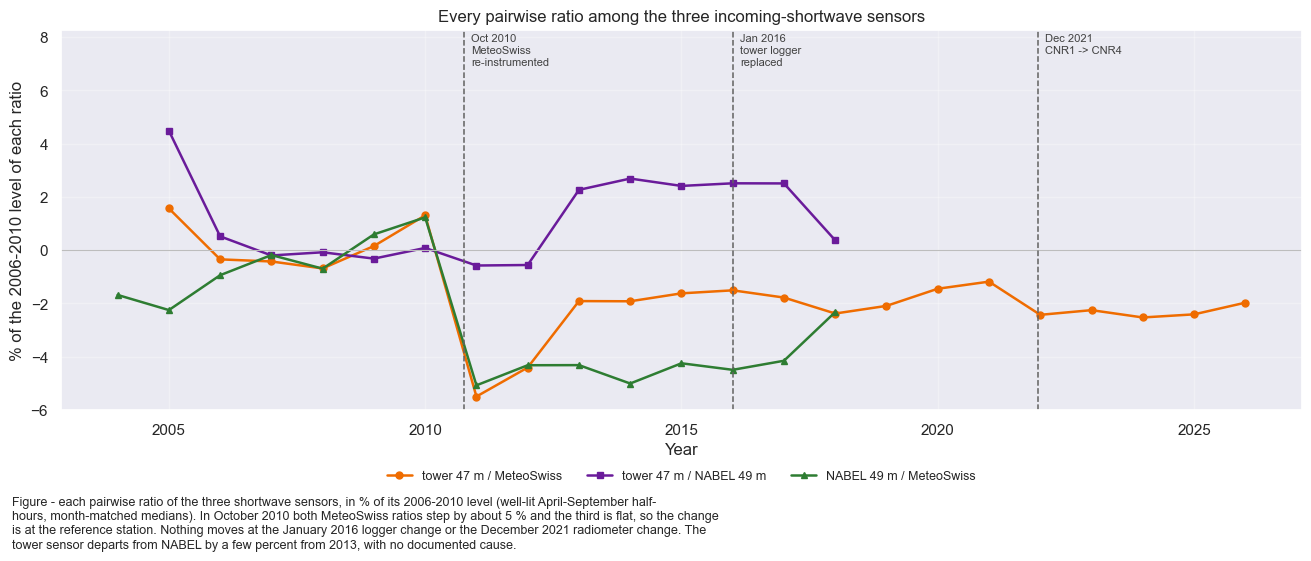

In [37]:

# The three ratios drawn together, with the three dates this section is about marked on them. The
# tables above are two rows of this figure; the figure shows which changes are steps, which are
# drifts, and which pairs move together - none of which two window means can convey.
# Drawn after the fieldbook and reference-file evidence above has fixed the dates, so every marked
# date comes from a file rather than from a number written here.
fig, ax = plt.subplots(figsize=(13, 5.5), dpi=100, layout="constrained")
_rel = 100 * (ratio_table / ratio_table.loc[2006:2010].mean() - 1)
for (_label, _colour, _marker) in [('tower 47 m / MeteoSwiss', '#EF6C00', 'o'),
                                   ('tower 47 m / NABEL 49 m', '#6A1B9A', 's'),
                                   ('NABEL 49 m / MeteoSwiss', '#2E7D32', '^')]:
    ax.plot(_rel.index, _rel[_label], color=_colour, lw=1.8, marker=_marker, ms=5, label=_label)
ax.axhline(0, color='#BDBDBD', lw=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("% of the 2006-2010 level of each ratio")
ax.set_title("Every pairwise ratio among the three incoming-shortwave sensors")
ax.grid(alpha=0.3)

# Headroom at the top so the event labels sit above the lines rather than across the legend.
_lo, _hi = ax.get_ylim()
ax.set_ylim(_lo, _hi + 0.30 * (_hi - _lo))
_top = ax.get_ylim()[1]
for _x, _text in [(_diffuse_start.year + 0.75, 'Oct 2010\nMeteoSwiss\nre-instrumented'),
                  (BREAK_YEAR, f'Jan {BREAK_YEAR}\ntower logger\nreplaced'),
                  (CNR4_YEAR - 0.05, f'Dec {CNR4_YEAR - 1}\nCNR1 -> CNR4')]:
    ax.axvline(_x, color='#616161', lw=1.1, ls='--')
    ax.text(_x + 0.15, _top - 0.15, _text, fontsize=8, color='#424242', va='top')
ax.legend(fontsize=9, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.13),
          frameon=False)
figcap(fig, "each pairwise ratio of the three shortwave sensors, in % of its 2006-2010 level "
            "(well-lit April-September half-hours, month-matched medians). In October 2010 both "
            "MeteoSwiss ratios step by about 5 % and the third is flat, so the change is at the "
            "reference station. Nothing moves at the January 2016 logger change or the December "
            "2021 radiometer change. The tower sensor departs from NABEL by a few percent from "
            "2013, with no documented cause.")


#### 📊 Plot: tower against NABEL either side of 2016

C:\Users\holukas\AppData\Local\Temp\ipykernel_14868\1644203161.py:27: RuntimeWarning: divide by zero encountered in divide
  axs[1].plot(_grid, 100 * ((_slope * _grid + _icpt) / _grid - 1), color=_colour, lw=2.2,


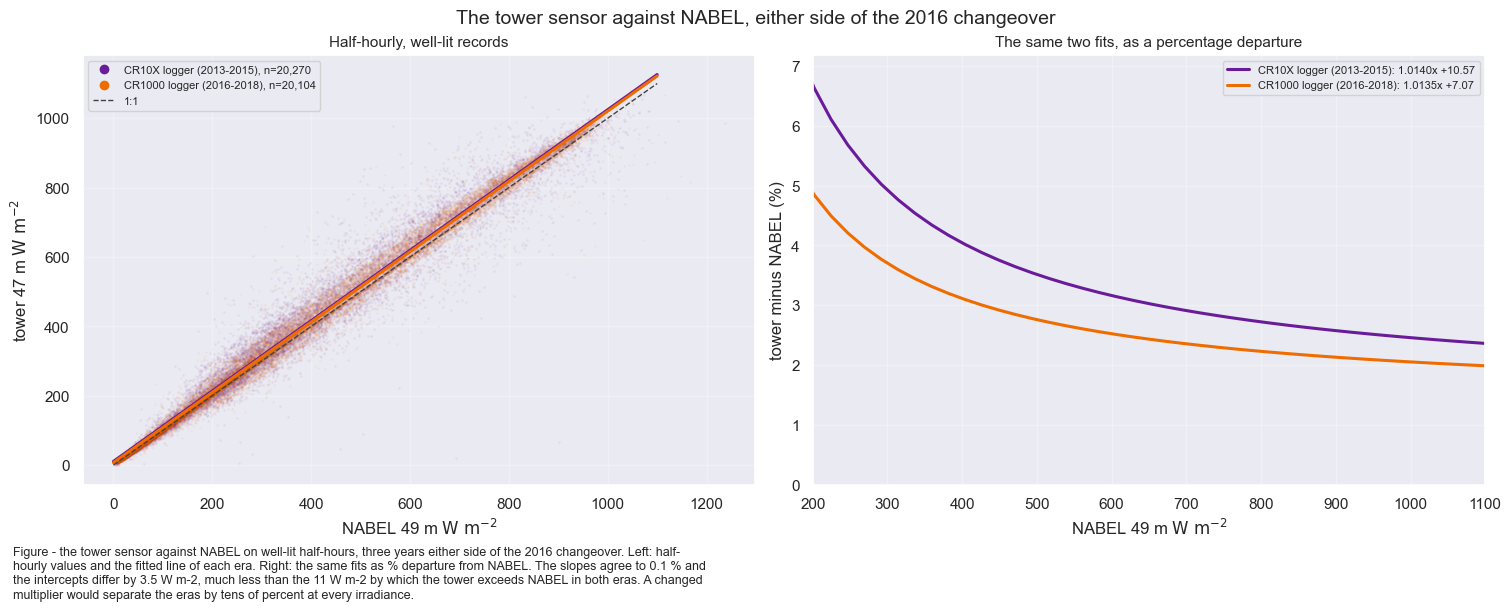

In [38]:
# The 2016 changeover drawn as the relationship it would have moved. If the acquisition change had
# rescaled the series, the two eras would fall on visibly different lines against a sensor that
# did not change; a step in the intercept would show as a vertical offset and a gain change as a
# different slope.
_lit_era = (POTRAD > WELL_LIT)
fig, axs = plt.subplots(ncols=2, figsize=(15, 6), dpi=100, layout='constrained')
fig.suptitle(f"The tower sensor against NABEL, either side of the {BREAK_YEAR} changeover",
             fontsize=14)

_eras = [(f'CR10X logger (2013-2015)', (2013, 2015), '#6A1B9A'),
         (f'CR1000 logger ({BREAK_YEAR}-2018)', (BREAK_YEAR, 2018), '#EF6C00')]
_fits = {}
for _label, (_y0, _y1), _colour in _eras:
    _sel = _lit_era & (swin_2004_2026.index.year >= _y0) & (swin_2004_2026.index.year <= _y1)
    _j = swin_2004_2026.loc[_sel, ['SW_IN_T1_47_1', 'SW_IN_NABEL_T1_49_1']].dropna()
    _slope, _icpt = np.polyfit(_j['SW_IN_NABEL_T1_49_1'].to_numpy(),
                               _j['SW_IN_T1_47_1'].to_numpy(), 1)
    _fits[_label] = (_slope, _icpt, len(_j))
    axs[0].scatter(_j['SW_IN_NABEL_T1_49_1'], _j['SW_IN_T1_47_1'], s=1, alpha=0.04,
                   color=_colour, rasterized=True)
    axs[0].plot([], [], 'o', color=_colour, label=f"{_label}, n={len(_j):,}")

_grid = np.linspace(0, 1100, 50)
for _label, (_y0, _y1), _colour in _eras:
    _slope, _icpt, _n = _fits[_label]
    axs[0].plot(_grid, _slope * _grid + _icpt, color=_colour, lw=2.2)
    axs[1].plot(_grid, 100 * ((_slope * _grid + _icpt) / _grid - 1), color=_colour, lw=2.2,
                label=f"{_label}: {_slope:.4f}x {_icpt:+.2f}")
axs[0].plot([0, 1100], [0, 1100], color='#424242', lw=1.0, ls='--', label='1:1')
axs[0].set_xlabel(r'NABEL 49 m $\mathrm{W\ m^{-2}}$')
axs[0].set_ylabel(r'tower 47 m $\mathrm{W\ m^{-2}}$')
axs[0].set_title('Half-hourly, well-lit records', fontsize=11)
axs[0].legend(fontsize=8, loc='upper left')
axs[0].grid(alpha=0.25)

axs[1].axhline(0, color='#BDBDBD', lw=0.8)
# The percentage departure diverges as the denominator goes to zero, so the panel is limited
# to the range where the two eras are actually being compared.
axs[1].set_xlim(200, 1100)
_dep_vals = [100 * ((_fits[_l][0] * _x + _fits[_l][1]) / _x - 1)
             for _l, _, _ in _eras for _x in (200, 1100)]
axs[1].set_ylim(min(0, min(_dep_vals) - 0.5), max(_dep_vals) + 0.5)
axs[1].set_xlabel(r'NABEL 49 m $\mathrm{W\ m^{-2}}$')
axs[1].set_ylabel('tower minus NABEL (%)')
axs[1].set_title('The same two fits, as a percentage departure', fontsize=11)
axs[1].legend(fontsize=8)
axs[1].grid(alpha=0.3)

_slopes = [_fits[_l][0] for _l, _, _ in _eras]
_icpts = [_fits[_l][1] for _l, _, _ in _eras]
figcap(fig, f"the tower sensor against NABEL on well-lit half-hours, three years either side of "
            f"the {BREAK_YEAR} changeover. Left: half-hourly values and the fitted line of each "
            f"era. Right: the same fits as % departure from NABEL. The slopes agree to "
            f"{100 * abs(_slopes[1] - _slopes[0]) / _slopes[0]:.1f} % and the intercepts differ by "
            f"{abs(_icpts[1] - _icpts[0]):.1f} W m-2, much less than the "
            f"{abs(_icpts[0]):.0f} W m-2 by which the tower exceeds NABEL in both eras. A changed "
            f"multiplier would separate the eras by tens of percent at every irradiance.")

### 7️⃣ What is left unexplained

The tower sensor departs from **both** references from 2013 by a few percent and later returns.
It is not a step, and the fieldbook records no calibration of this CNR1 between 2005 and 2021. The
departure is within the field uncertainty of this pyranometer class, and the evidence cannot
separate a drift of the tower sensor from one of NABEL. It is **recorded, not corrected**.

#### 📋 Table: departure of the tower sensor, 2013-2017

In [39]:

# What the same scan leaves unexplained, stated rather than left to be found. The tower sensor
# departs from both references over 2013-2015 and returns; nothing in the fieldbook covers it.
_dep = pd.DataFrame({_l: RATIOS[_l] for _l in RATIOS})
_dep = 100 * (_dep / _dep.loc[2006:2010].mean() - 1)
DEPARTURE_YEARS = [2013, 2014, 2015, 2016, 2017]
tabcap("the tower sensor against both references during the departure, in % of the "
       "2006-2010 level of each ratio")
display(_dep.loc[DEPARTURE_YEARS].round(2))

_worst = _dep.loc[DEPARTURE_YEARS, 'tower 47 m / NABEL 49 m'].abs().max()
print(f"\nlargest departure of the tower sensor from NABEL over {DEPARTURE_YEARS[0]}-"
      f"{DEPARTURE_YEARS[-1]}: {_worst:.2f} %")
print("It is not corrected here: it is within the field uncertainty of a pyranometer of this "
      "class, it develops rather than steps, and no maintenance record covers it. It is recorded "
      "as a limitation of the product and examined in RADIATION_SENSOR_CONTINUITY.ipynb.")
assert _worst < 5.0, (
    "the unexplained departure has grown past the field uncertainty of the instrument - it can no "
    "longer be left uncorrected on the grounds given here")


Table - the tower sensor against both references during the departure, in % of the 2006-2010 level
of each ratio



,tower 47 m / MeteoSwiss,tower 47 m / NABEL 49 m,NABEL 49 m / MeteoSwiss
year,,,
2013,-1.91,2.27,-4.32
2014,-1.92,2.69,-5.01
2015,-1.62,2.41,-4.25
2016,-1.51,2.51,-4.50
2017,-1.78,2.51,-4.16



largest departure of the tower sensor from NABEL over 2013-2017: 2.69 %
It is not corrected here: it is within the field uncertainty of a pyranometer of this class, it develops rather than steps, and no maintenance record covers it. It is recorded as a limitation of the product and examined in RADIATION_SENSOR_CONTINUITY.ipynb.


#### Summary

`SW_IN_T1_47_1` is **homogeneous across the January 2016 acquisition change** (same sensor,
constant and level) and across the December 2021 radiometer replacement. No correction is applied
and no `_HOMOGENIZED` column is exported. Two limitations are documented on the `SW_IN` page: the
unattributed 2 % departure from 2013, and the October 2010 level change of the MeteoSwiss driver.
The assertions above make the notebook fail if a re-run finds a step at either changeover.

## 🟪 Prepare dataframes

Two periods are gap-filled separately: **2004-2018** with NABEL and Lägern as drivers, and
**2019-2026** with Lägern only. `SW_IN_NABEL_T1_49_1` is dropped from the second frame because it
is empty there.

In [40]:
swin_2004_2018 = swin_2004_2026.loc[swin_2004_2026.index.year <= 2018].copy()
swin_2004_2018

,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1,SW_IN_LAE_MS
TIMESTAMP_MIDDLE,,,
2004-01-01 00:15:00,NaN,0.0,NaN
2004-01-01 00:45:00,NaN,0.0,NaN
2004-01-01 01:15:00,NaN,0.0,NaN
2004-01-01 01:45:00,NaN,0.0,NaN
2004-01-01 02:15:00,NaN,0.0,NaN
...,...,...,...
2018-12-31 21:45:00,0.0,0.0,2.000000
2018-12-31 22:15:00,0.0,0.0,2.000000
2018-12-31 22:45:00,0.0,0.0,2.000000


In [41]:
swin_2019_2026 = swin_2004_2026.loc[swin_2004_2026.index.year >= 2019].copy()
swin_2019_2026 = swin_2019_2026.drop('SW_IN_NABEL_T1_49_1', axis=1)
swin_2019_2026

,SW_IN_T1_47_1,SW_IN_LAE_MS
TIMESTAMP_MIDDLE,,
2019-01-01 00:15:00,0.0,2.333333
2019-01-01 00:45:00,0.0,2.000000
2019-01-01 01:15:00,0.0,2.000000
2019-01-01 01:45:00,0.0,2.000000
2019-01-01 02:15:00,0.0,2.000000
...,...,...
2026-09-30 21:45:00,0.0,1.000000
2026-09-30 22:15:00,0.0,1.333333
2026-09-30 22:45:00,0.0,2.000000


***

## 🟥 Gap-filling ETH (2004-2018)
- Drivers: NABEL (49 m, same tower) and MeteoSwiss Lägern, both as measured

`SWINGapFillerXGBoost` computes `SW_IN_POT` from the site coordinates, splits day from night, sets
nighttime gaps to zero and fills daytime gaps with XGBoost. Negatives are clipped.
`correct_nighttime_offset=True` finds nothing left after the correction above.

Both drivers enter as measured, so the target never predicts itself. Where both are missing, the
gap-filler falls back to a timestamp-only model (flag `2`). With a driver present,
`interpolate_short_gaps='auto'` resolves to off, so short daytime gaps are modelled, not
interpolated.

| Run | Drivers (`context_df`) |
|---|---|
| ETH 2004-2018 | NABEL (measured) + Lägern |
| ETH 2019-2026 | Lägern |

### Run gap-filling

`context_df` supplies the two radiation measurements. NABEL is closer but gappy and stops in 2018;
Lägern is continuous.

In [42]:
%%time

TARGET = "SW_IN_T1_47_1"

gf_eth_2004_2018 = dv.gapfilling.SWINGapFillerXGBoost(
    series=swin_2004_2018[TARGET],
    lat=SITE_LAT,
    lon=SITE_LON,
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
    # Both drivers as measured. NABEL is gappy; Lägern (99.6% present) covers those gaps,
    # so neither the tower nor a model-filled series is used to predict the tower.
    context_df=swin_2004_2018[['SW_IN_NABEL_T1_49_1', REFCOL]],
    correct_nighttime_offset=True,
    # interpolate_short_gaps left at 'auto': drivers are given, so interpolation stays OFF
    reduce_features=True,
    verbose=1,
    # XGBoost hyperparameters are left at the class defaults (n_estimators, max_depth,
    # early_stopping_rounds, random_state). They are tuned for SW_IN and keep a run
    # reproducible; only n_jobs is set here.
    n_jobs=-1,
)
gf_eth_2004_2018.run()

──────────────────────────────── SW_IN Gap-Filling (SW_IN_T1_47_1) ─────────────────────────────────

Output()

> Step 1: Correcting nighttime sensor offset (2.6s)

> Step 2: Computing potential radiation and day/night split (0.0s, 137361 daytime / 125631 
nighttime records)

> Gaps to fill: 17708 daytime, 15447 nighttime

...

> Step 6: Reducing features (SHAP vs random benchmark) and retraining (2.0s)

Output()

> Step 7: Filling daytime gaps (SHAP importances over up to 10000 records) (8.2s)

v Done in 15.8s - 33155 records filled (33155 gaps total)

CPU times: total: 2min 55s
Wall time: 23 s


### Report

In [43]:
gf_eth_2004_2018.report()

───────────────────────────── SW_IN Gap-Filling Report: SW_IN_T1_47_1 ──────────────────────────────

Algorithm: physics-aware partitioning + XGBoost
    Nighttime gaps  -> set to 0 W m-2 (no incoming solar radiation)
    Daytime gaps    -> XGBoost trained on daytime observations
    Day/night split -> SW_IN_POT (potential radiation) vs threshold

──────────────────────────────────────────── Parameters ────────────────────────────────────────────

Site latitude              47.478333
  Site longitude             8.364389
  UTC offset                 1
  Nighttime threshold        0.001 W m-2  (SW_IN_POT < threshold -> night)
  Correct nighttime offset   True
  Reduce features (SHAP)     True
  context drivers            ['SW_IN_NABEL_T1_49_1', 'SW_IN_LAE_MS']

─────────────────────────────────────── Feature engineering ────────────────────────────────────────

...

MSE      868.2587

RMSE     29.4662

MAPE     64473181249663.6094

MAXE     729.3863

R2       0.9879

### Results: scores and feature importances

#### 📋 Table: held-out scores, 2004-2018

In [44]:
r = gf_eth_2004_2018.results
tabcap("held-out scores of the SW_IN_T1_47_1 (2004-2018) daytime model")
display(pd.Series(r.scores_traintest))

Table - held-out scores of the SW_IN_T1_47_1 (2004-2018) daytime model



mae      1.612012e+01
medae    6.344359e+00
mse      1.082076e+03
rmse     3.289493e+01
mape     5.887277e+13
maxe     6.607116e+02
r2       9.847740e-01
dtype: float64

#### 📋 Table: records per provenance code, 2004-2018

In [45]:
tabcap("records per provenance code, SW_IN_T1_47_1 (2004-2018)")
display(r.flag.value_counts().sort_index().rename(index=FLAG_LEGEND))

Table - records per provenance code, SW_IN_T1_47_1 (2004-2018)



flag
0 = observed                                                                           229837
1 = daytime gap, filled by the XGBoost model                                            17011
2 = daytime gap, filled by the timestamp-only fallback model (a driver was missing)       697
3 = nighttime gap, set to zero by physics                                               15447
Name: count, dtype: int64

#### 📋 Table: driver importance, 2004-2018

In [46]:
tabcap("driver importance of the SW_IN_T1_47_1 (2004-2018) daytime model")
display(r.feature_importances)

Table - driver importance of the SW_IN_T1_47_1 (2004-2018) daytime model



,SHAP_IMPORTANCE,SHAP_SD
SW_IN_NABEL_T1_49_1,203.099503,132.247116
SW_IN_LAE_MS,11.639704,8.465756
.SW_IN_NABEL_T1_49_1_ROLLMEDIAN4,7.505960,6.374772
.SW_IN_NABEL_T1_49_1_MEAN4,5.144228,3.136867
.SW_IN_LAE_MS_MEAN4,3.874487,6.337811
...,...,...
.SW_IN_NABEL_T1_49_1_SD8,0.742543,0.863851
.WEEK_SIN,0.625209,0.687767
.DOY_SIN,0.611421,1.062662
.SW_IN_LAE_MS_SD8,0.576087,0.910506


#### 📊 Plot: driver importance, 2004-2018

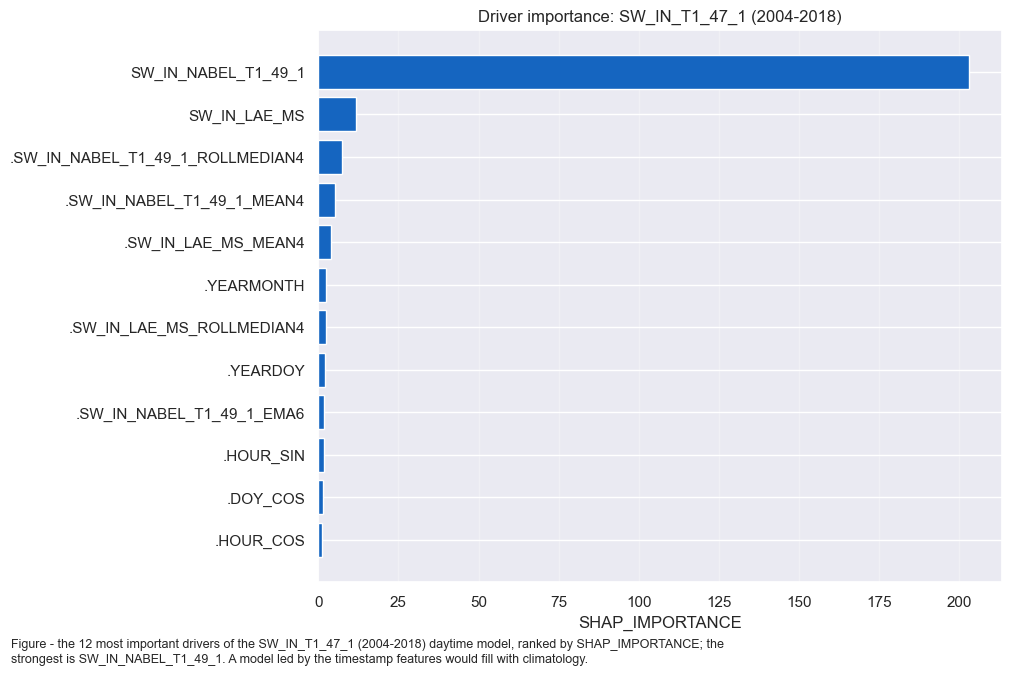

In [47]:
plot_feature_importances(r, label="SW_IN_T1_47_1 (2004-2018)");

### Add gap-filled series to dataframe

#### 📋 Table: exported flag, 2004-2018

In [48]:
gapfilled_eth_2004_2018 = gf_eth_2004_2018.results.gapfilled.rename(f"{TARGET}_gfXG")
swin_2004_2018[gapfilled_eth_2004_2018.name] = gapfilled_eth_2004_2018

# This flag IS exported (see the export section). Held as a standalone series rather than a
# dataframe column so the plotting cells below keep showing radiation only.
flag_eth_2004_2018 = gf_eth_2004_2018.results.flag.rename(f"FLAG_{TARGET}_ISFILLED")
tabcap("the exported flag for SW_IN_T1_47_1 (2004-2018), by code")
display(flag_eth_2004_2018.value_counts().sort_index().rename(index=FLAG_LEGEND))

Table - the exported flag for SW_IN_T1_47_1 (2004-2018), by code



FLAG_SW_IN_T1_47_1_ISFILLED
0 = observed                                                                           229837
1 = daytime gap, filled by the XGBoost model                                            17011
2 = daytime gap, filled by the timestamp-only fallback model (a driver was missing)       697
3 = nighttime gap, set to zero by physics                                               15447
Name: count, dtype: int64

#### 📋 Table: measured and gap-filled column, 2004-2018

In [49]:
tabcap("measured and gap-filled column, 2004-2018; the gap-filled column has no gaps")
swin_2004_2018[[TARGET, gapfilled_eth_2004_2018.name]].describe()

Table - measured and gap-filled column, 2004-2018; the gap-filled column has no gaps



,SW_IN_T1_47_1,SW_IN_T1_47_1_gfXG
count,229837.000000,262992.000000
mean,142.603195,144.261782
std,236.721217,238.046170
min,0.000000,0.000000
25%,0.000000,0.000000
50%,3.657932,4.197031
75%,190.252314,195.239186
max,1111.028655,1111.028655


#### 📊 Plot: measured, gap-filled and the fills alone, 2004-2018

The bottom panel shows the fills alone, where an implausible level or a long block of fills is
visible.

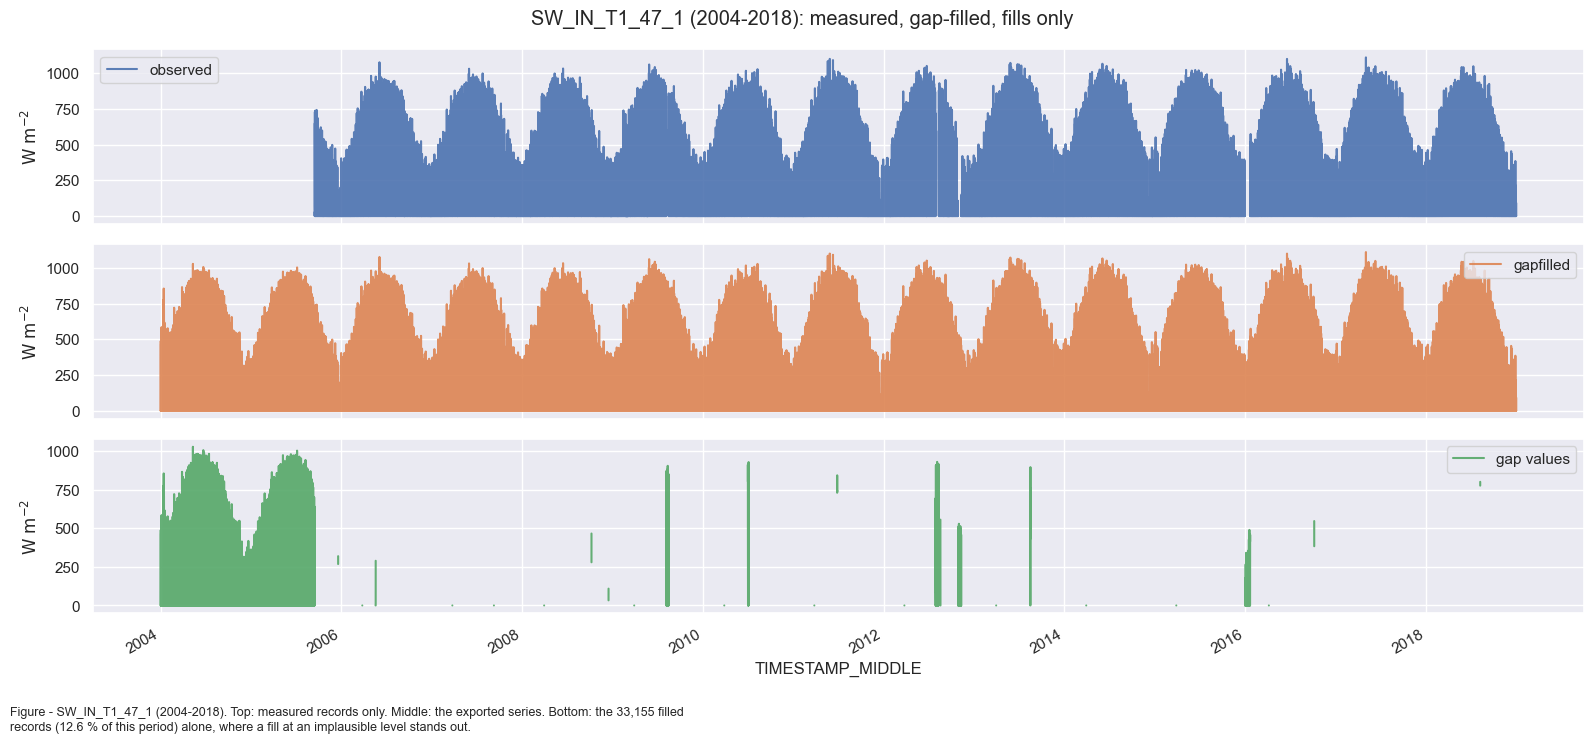

In [50]:
plot_gapfill_panels(gf_eth_2004_2018.results, label="SW_IN_T1_47_1 (2004-2018)");

#### 📊 Plot: predicted against measured on held-out data, 2004-2018

Records the model never saw in training. A tilt in the residuals means bias; a widening cone is
expected for radiation.

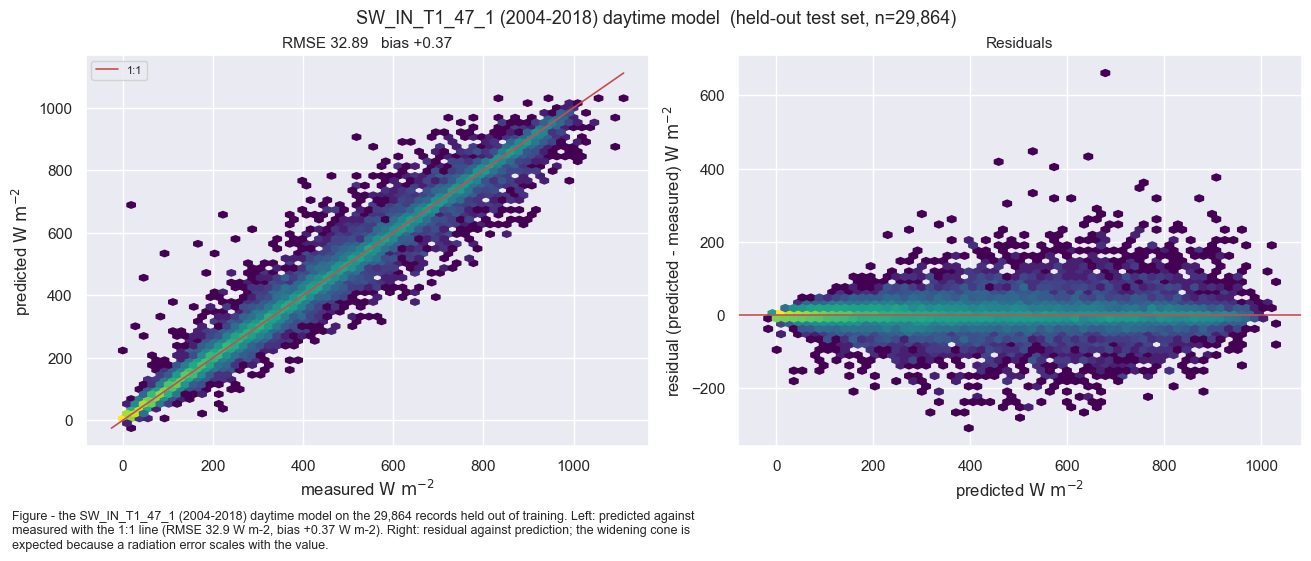

In [51]:
plot_pred_vs_measured(gf_eth_2004_2018.daytime_model_, label="SW_IN_T1_47_1 (2004-2018)");

### 📋 Table: the 2004-2018 frame

In [52]:
tabcap("the 2004-2018 frame with its gap-filled column added")
display(swin_2004_2018)
swin_2004_2018.describe()

Table - the 2004-2018 frame with its gap-filled column added



,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1,SW_IN_LAE_MS,SW_IN_T1_47_1_gfXG
TIMESTAMP_MIDDLE,,,,
2004-01-01 00:15:00,NaN,0.0,NaN,0.0
2004-01-01 00:45:00,NaN,0.0,NaN,0.0
2004-01-01 01:15:00,NaN,0.0,NaN,0.0
2004-01-01 01:45:00,NaN,0.0,NaN,0.0
2004-01-01 02:15:00,NaN,0.0,NaN,0.0
...,...,...,...,...
2018-12-31 21:45:00,0.0,0.0,2.000000,0.0
2018-12-31 22:15:00,0.0,0.0,2.000000,0.0
2018-12-31 22:45:00,0.0,0.0,2.000000,0.0


,SW_IN_T1_47_1,SW_IN_NABEL_T1_49_1,SW_IN_LAE_MS,SW_IN_T1_47_1_gfXG
count,229837.000000,262774.000000,261392.000000,262992.000000
mean,142.603195,140.035108,139.777236,144.261782
std,236.721217,233.702051,229.285462,238.046170
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,2.000000,0.000000
50%,3.657932,2.495635,5.333333,4.197031
75%,190.252314,186.456335,186.000000,195.239186
max,1111.028655,1236.721293,1155.333333,1111.028655


***

### Plots

#### 📊 Plot: heatmaps 2004-2018, before and after gap-filling

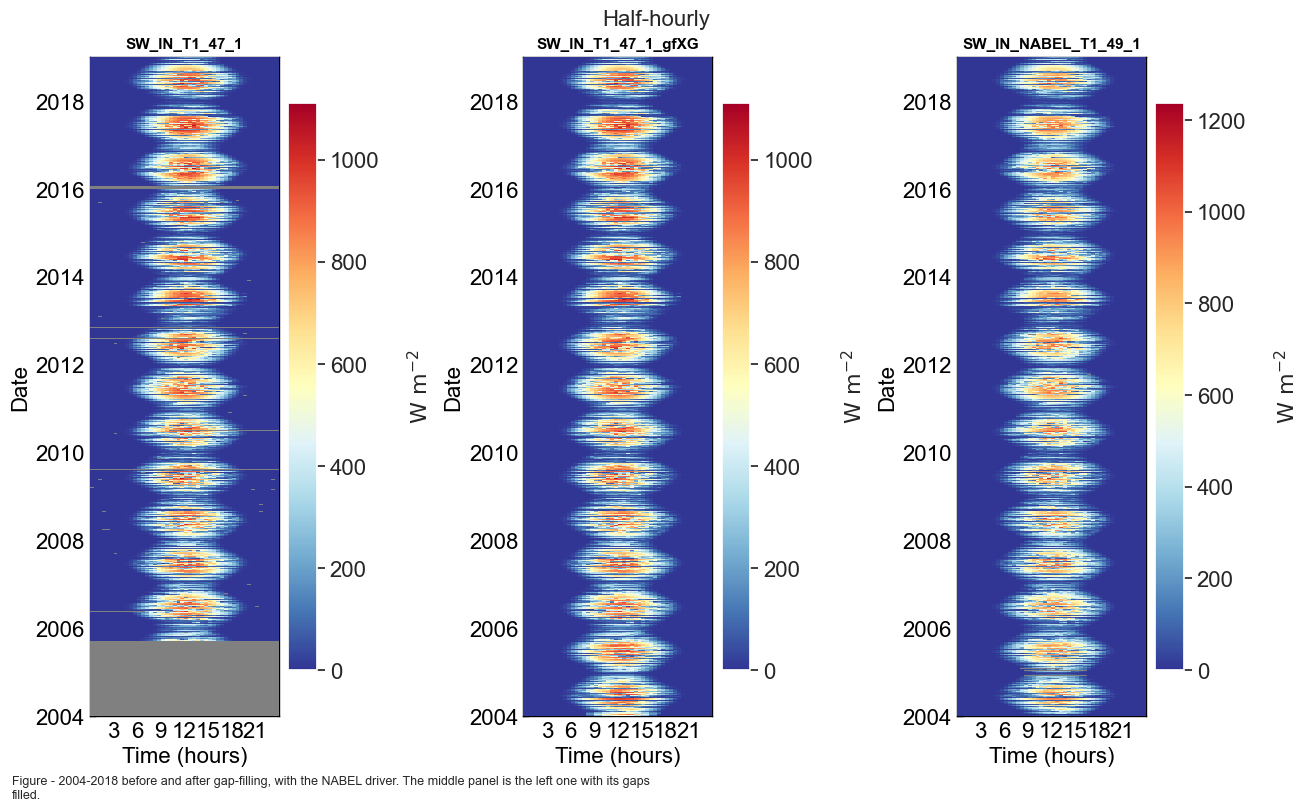

In [53]:
fig, axs = plt.subplots(ncols=3, figsize=(13, 8), dpi=100, layout="constrained")
fig.suptitle(f'Half-hourly', fontsize=16)
for _ax, _col in zip(axs, ['SW_IN_T1_47_1', 'SW_IN_T1_47_1_gfXG', 'SW_IN_NABEL_T1_49_1']):
    dv.plotting.HeatmapDateTime(series=swin_2004_2018[_col]).plot(
        ax=_ax, cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
        format_style=dv.plotting.FormatStyle(title=_col, title_fontsize=11))
figcap(fig, "2004-2018 before and after gap-filling, with the NABEL driver. The middle panel "
            "is the left one with its gaps filled.")

#### 📊 Plot: time series 2004-2018

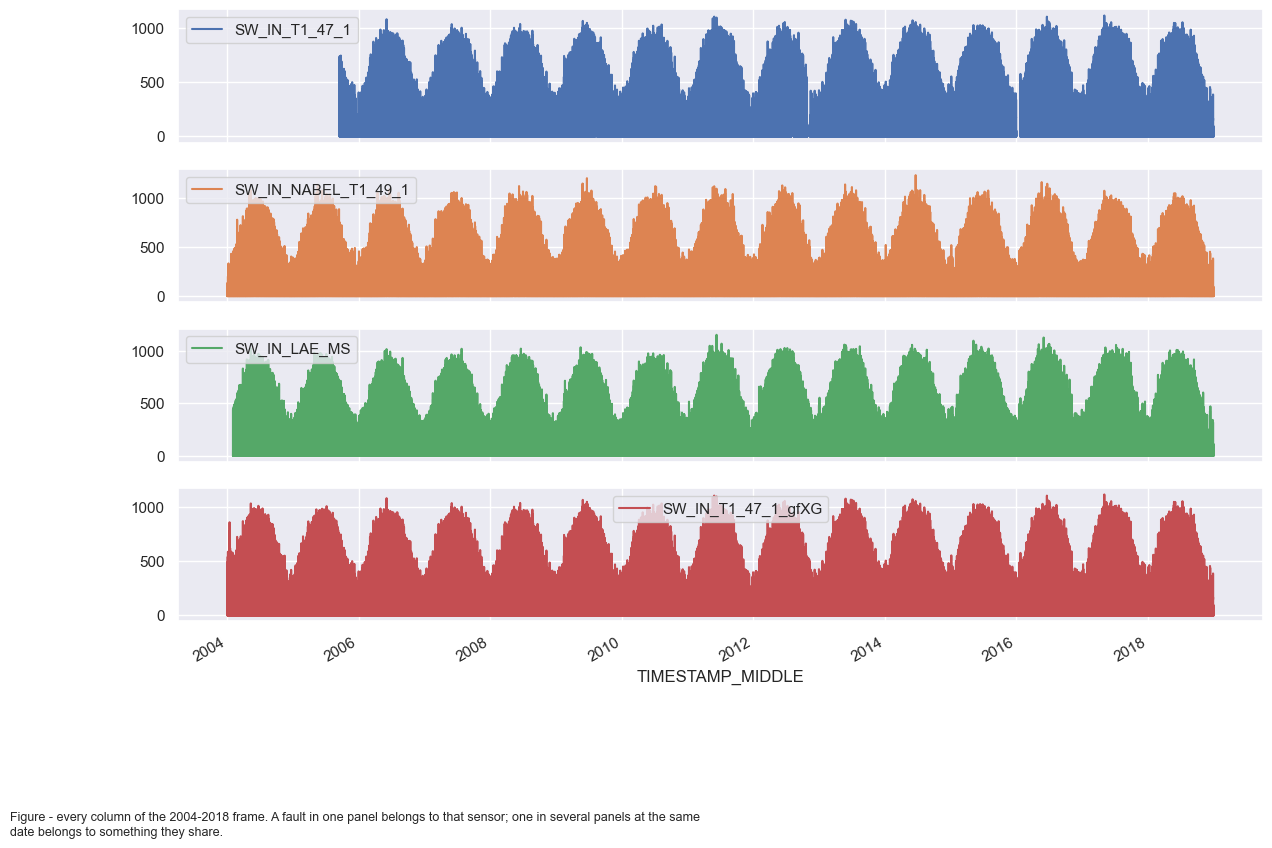

In [54]:
_axs = swin_2004_2018.plot(subplots=True, x_compat=True, figsize=(14, 9))
figcap(_axs[0].get_figure(), "every column of the 2004-2018 frame. A fault in one "
                             "panel belongs to that sensor; one in several panels at the same "
                             "date belongs to something they share.");

***

## 🟧 Gap-filling ETH (2019-2026)
- From `mst` (2019-2021) and `diive` meteoscreening (2022-2026)
- NABEL has stopped. **MeteoSwiss Lägern is the only radiation driver.**

::: {.callout-note title="Flag 1 in this period"}
Fills follow the sky state measured at Lägern, 2.5 km away at 845 m. With one driver instead of
two, flag `1` records here are less certain than in 2004-2018.
:::

### Run gap-filling

In [55]:
%%time

TARGET = "SW_IN_T1_47_1"

gf_eth_2019_2026 = dv.gapfilling.SWINGapFillerXGBoost(
    series=swin_2019_2026[TARGET],
    lat=SITE_LAT,
    lon=SITE_LON,
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
    context_df=swin_2019_2026[[REFCOL]],  # Lägern: the only radiation driver in this period
    correct_nighttime_offset=True,
    # interpolate_short_gaps left at 'auto'. A driver is now given, so this resolves to OFF
    # and no longer overwrites the model fills, which are now informed by a real sky state.
    reduce_features=True,
    verbose=1,
    # XGBoost hyperparameters are left at the class defaults (n_estimators, max_depth,
    # early_stopping_rounds, random_state). They are tuned for SW_IN and keep a run
    # reproducible; only n_jobs is set here.
    n_jobs=-1,
)
gf_eth_2019_2026.run()

──────────────────────────────── SW_IN Gap-Filling (SW_IN_T1_47_1) ─────────────────────────────────

Output()

> Step 1: Correcting nighttime sensor offset (1.2s)

> Step 2: Computing potential radiation and day/night split (0.0s, 71438 daytime / 64402 nighttime
records)

> Gaps to fill: 400 daytime, 447 nighttime

...

> Step 6: Reducing features (SHAP vs random benchmark) and retraining (3.3s)

Output()

> Step 7: Filling daytime gaps (SHAP importances over up to 10000 records) (1.2s)

v Done in 7.7s - 847 records filled (847 gaps total)

CPU times: total: 1min 24s
Wall time: 7.66 s


### Report

In [56]:
gf_eth_2019_2026.report()

───────────────────────────── SW_IN Gap-Filling Report: SW_IN_T1_47_1 ──────────────────────────────

Algorithm: physics-aware partitioning + XGBoost
    Nighttime gaps  -> set to 0 W m-2 (no incoming solar radiation)
    Daytime gaps    -> XGBoost trained on daytime observations
    Day/night split -> SW_IN_POT (potential radiation) vs threshold

──────────────────────────────────────────── Parameters ────────────────────────────────────────────

Site latitude              47.478333
  Site longitude             8.364389
  UTC offset                 1
  Nighttime threshold        0.001 W m-2  (SW_IN_POT < threshold -> night)
  Correct nighttime offset   True
  Reduce features (SHAP)     True
  context drivers            ['SW_IN_LAE_MS']

─────────────────────────────────────── Feature engineering ────────────────────────────────────────

...

MSE      1904.7707

RMSE     43.6437

MAPE     156062469162826.0000

MAXE     561.9248

R2       0.9754

### Results: scores and feature importances

#### 📋 Table: held-out scores, 2019-2026

In [57]:
r = gf_eth_2019_2026.results
tabcap("held-out scores of the SW_IN_T1_47_1 (2019-2026) daytime model")
display(pd.Series(r.scores_traintest))

Table - held-out scores of the SW_IN_T1_47_1 (2019-2026) daytime model



mae      2.792827e+01
medae    1.163583e+01
mse      2.868097e+03
rmse     5.355462e+01
mape     1.838459e+14
maxe     5.619248e+02
r2       9.628194e-01
dtype: float64

#### 📋 Table: records per provenance code, 2019-2026

In [58]:
tabcap("records per provenance code, SW_IN_T1_47_1 (2019-2026)")
display(r.flag.value_counts().sort_index().rename(index=FLAG_LEGEND))

Table - records per provenance code, SW_IN_T1_47_1 (2019-2026)



flag
0 = observed                                    134993
1 = daytime gap, filled by the XGBoost model       400
3 = nighttime gap, set to zero by physics          447
Name: count, dtype: int64

#### 📋 Table: driver importance, 2019-2026

In [59]:
tabcap("driver importance of the SW_IN_T1_47_1 (2019-2026) daytime model")
display(r.feature_importances)

Table - driver importance of the SW_IN_T1_47_1 (2019-2026) daytime model



,SHAP_IMPORTANCE,SHAP_SD
SW_IN_LAE_MS,195.323456,119.404892
SW_IN_POT,15.730151,10.081856
.SW_IN_LAE_MS_ROLLMEDIAN4,15.154000,16.851912
.SW_IN_LAE_MS_MEAN4,7.678581,9.845778
.SW_IN_LAE_MS_EMA6,6.137161,5.001291
.RECORDNUMBER,5.916711,4.255084
.SW_IN_LAE_MS_SD24,5.679875,3.063909
.YEARWEEK,5.041324,4.298024
.SW_IN_LAE_MS_ROLLMEDIAN8,4.589715,4.834152
.SW_IN_LAE_MS_EMA24,4.473022,2.780865


#### 📊 Plot: driver importance, 2019-2026

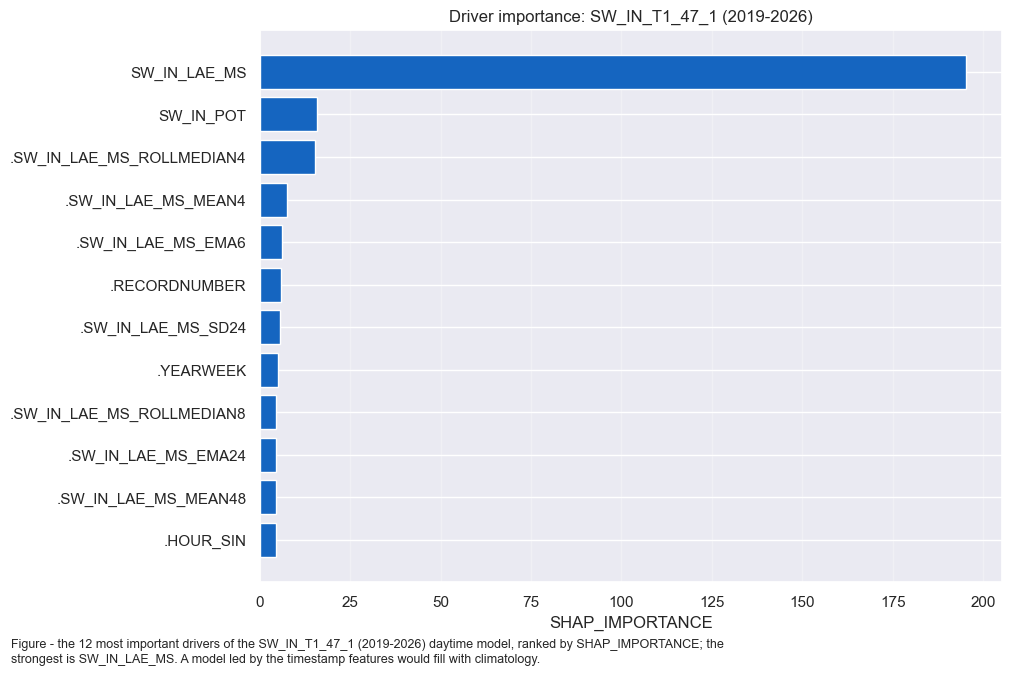

In [60]:
plot_feature_importances(r, label="SW_IN_T1_47_1 (2019-2026)");

### Add gap-filled series to dataframe

#### 📋 Table: exported flag, 2019-2026

In [61]:
gapfilled_eth_2019_2026 = gf_eth_2019_2026.results.gapfilled.rename(f"{TARGET}_gfXG")
swin_2019_2026[gapfilled_eth_2019_2026.name] = gapfilled_eth_2019_2026

# This flag IS exported (see the export section).
flag_eth_2019_2026 = gf_eth_2019_2026.results.flag.rename(f"FLAG_{TARGET}_ISFILLED")
tabcap("the exported flag for SW_IN_T1_47_1 (2019-2026), by code")
display(flag_eth_2019_2026.value_counts().sort_index().rename(index=FLAG_LEGEND))

Table - the exported flag for SW_IN_T1_47_1 (2019-2026), by code



FLAG_SW_IN_T1_47_1_ISFILLED
0 = observed                                    134993
1 = daytime gap, filled by the XGBoost model       400
3 = nighttime gap, set to zero by physics          447
Name: count, dtype: int64

#### 📋 Table: measured and gap-filled column, 2019-2026

In [62]:
tabcap("measured and gap-filled column, 2019-2026")
swin_2019_2026[[TARGET, gapfilled_eth_2019_2026.name]].describe()

Table - measured and gap-filled column, 2019-2026



,SW_IN_T1_47_1,SW_IN_T1_47_1_gfXG
count,134993.000000,135840.000000
mean,154.550862,154.097922
std,249.606115,249.213863
min,0.000000,0.000000
25%,0.000000,0.000000
50%,4.627382,4.561581
75%,216.411335,215.291406
max,1118.658439,1118.658439


#### 📊 Plot: measured, gap-filled and the fills alone, 2019-2026

The bottom panel shows the fills alone, where an implausible level or a long block of fills is
visible.

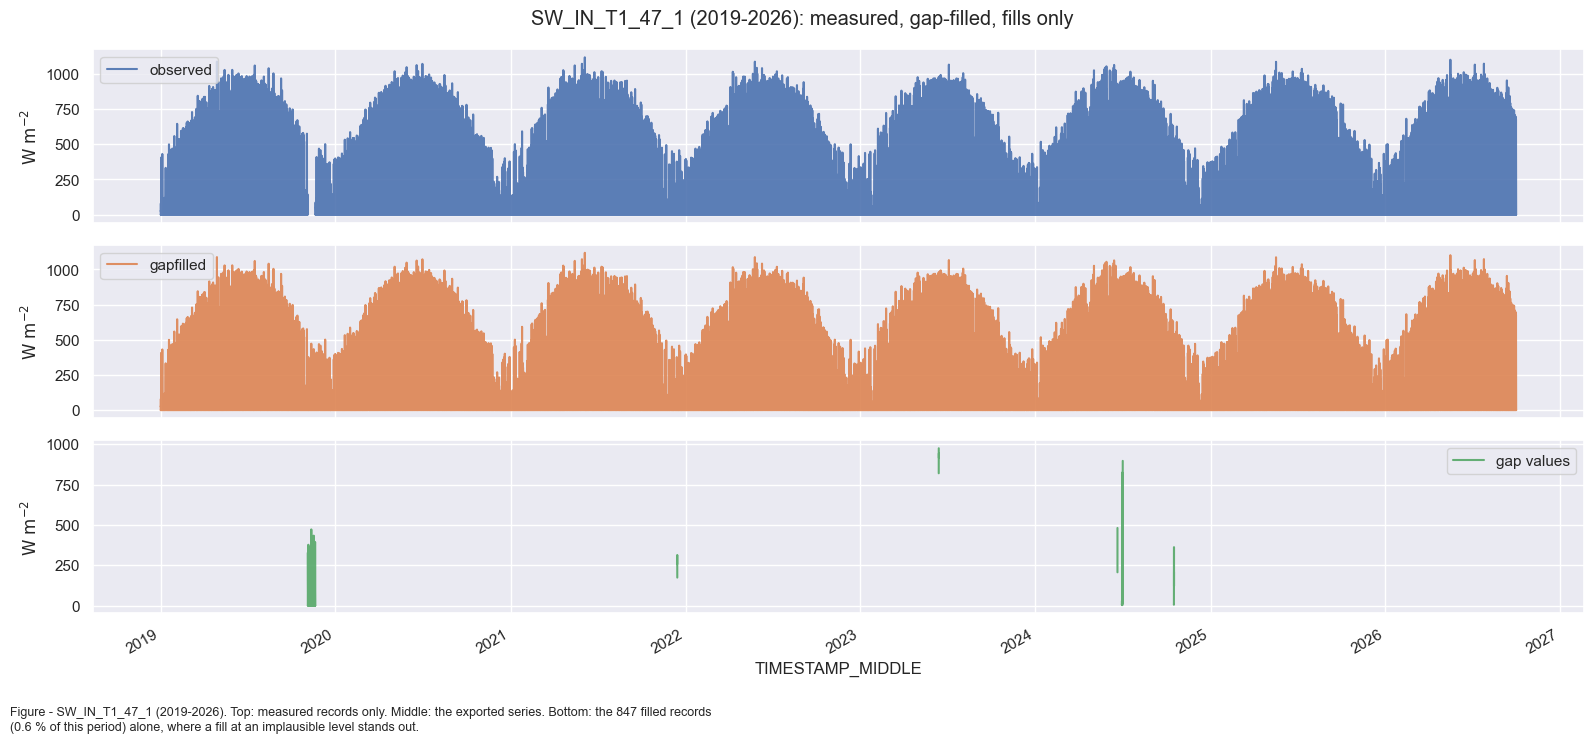

In [63]:
plot_gapfill_panels(gf_eth_2019_2026.results, label="SW_IN_T1_47_1 (2019-2026)");

#### 📊 Plot: predicted against measured on held-out data, 2019-2026

Records the model never saw in training. A tilt in the residuals means bias; a widening cone is
expected for radiation.

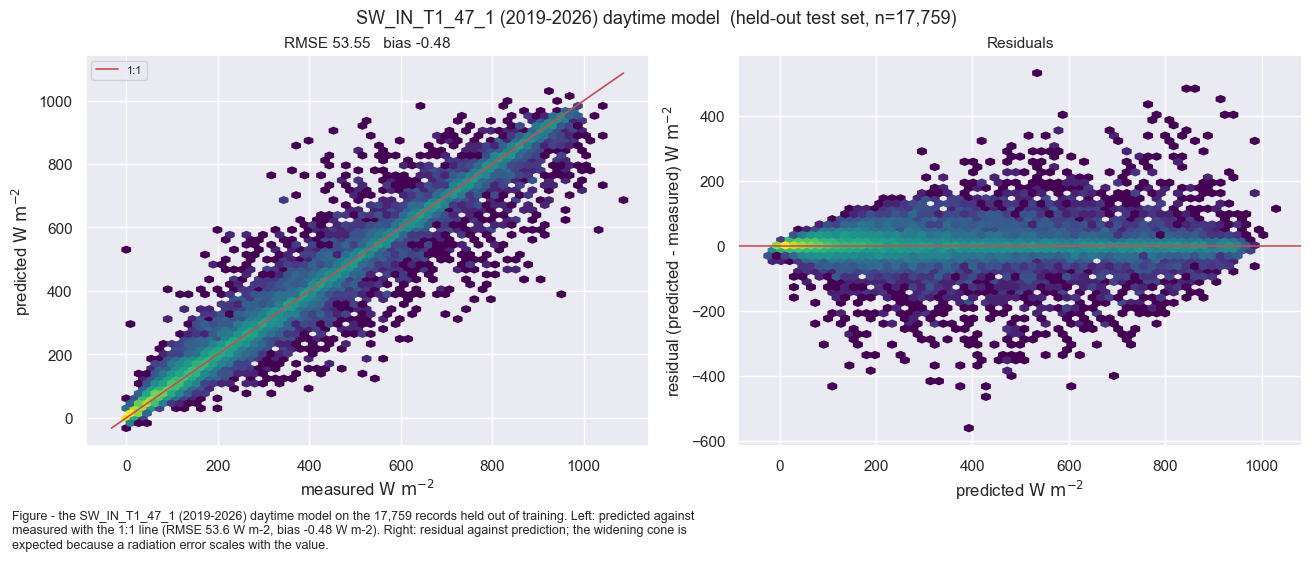

In [64]:
plot_pred_vs_measured(gf_eth_2019_2026.daytime_model_, label="SW_IN_T1_47_1 (2019-2026)");

### 📊 Plot: time series 2019-2026

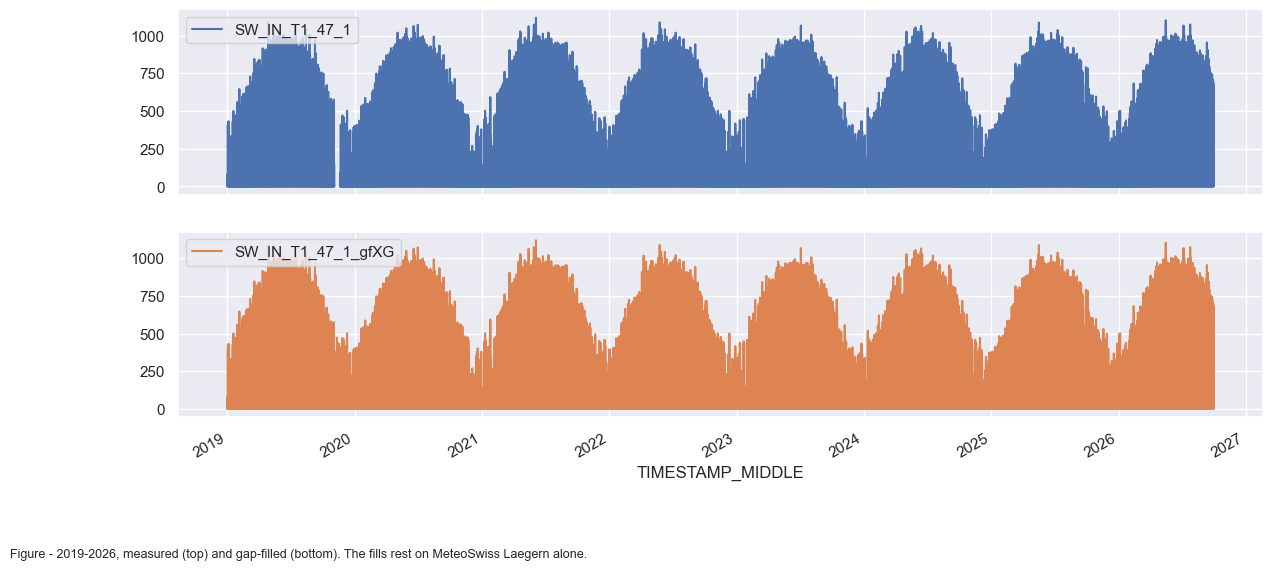

In [65]:
_axs = swin_2019_2026[[TARGET, gapfilled_eth_2019_2026.name]].plot(
    subplots=True, x_compat=True, figsize=(14, 6))
figcap(_axs[0].get_figure(), "2019-2026, measured (top) and gap-filled (bottom). "
                             "The fills rest on MeteoSwiss Laegern alone.");

### 📋 Table: the 2019-2026 frame

In [66]:
tabcap("the 2019-2026 frame with its gap-filled column added")
display(swin_2019_2026)
swin_2019_2026.describe()

Table - the 2019-2026 frame with its gap-filled column added



,SW_IN_T1_47_1,SW_IN_LAE_MS,SW_IN_T1_47_1_gfXG
TIMESTAMP_MIDDLE,,,
2019-01-01 00:15:00,0.0,2.333333,0.0
2019-01-01 00:45:00,0.0,2.000000,0.0
2019-01-01 01:15:00,0.0,2.000000,0.0
2019-01-01 01:45:00,0.0,2.000000,0.0
2019-01-01 02:15:00,0.0,2.000000,0.0
...,...,...,...
2026-09-30 21:45:00,0.0,1.000000,0.0
2026-09-30 22:15:00,0.0,1.333333,0.0
2026-09-30 22:45:00,0.0,2.000000,0.0


,SW_IN_T1_47_1,SW_IN_LAE_MS,SW_IN_T1_47_1_gfXG
count,134993.000000,135838.000000,135840.000000
mean,154.550862,149.977471,154.097922
std,249.606115,240.424094,249.213863
min,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.000000
50%,4.627382,6.666667,4.561581
75%,216.411335,207.666667,215.291406
max,1118.658439,1136.000000,1118.658439


***

## ➡️ Prepare dataframe for export

### 📋 Table: the exported frame

In [67]:
VALCOL = "SW_IN_T1_47_1_gfXG"
FLAGCOL = "FLAG_SW_IN_T1_47_1_ISFILLED"

# Values and flags come from the same gap-filling run per period, so they are paired
# before the two periods are stacked.
export_df = pd.concat([
    pd.concat([swin_2004_2018[VALCOL], flag_eth_2004_2018], axis=1),
    pd.concat([swin_2019_2026[VALCOL], flag_eth_2019_2026], axis=1),
], axis=0)
tabcap("the two gap-filled periods stacked into the frame that is exported")
export_df

Table - the two gap-filled periods stacked into the frame that is exported



,SW_IN_T1_47_1_gfXG,FLAG_SW_IN_T1_47_1_ISFILLED
TIMESTAMP_MIDDLE,,
2004-01-01 00:15:00,0.0,3
2004-01-01 00:45:00,0.0,3
2004-01-01 01:15:00,0.0,3
2004-01-01 01:45:00,0.0,3
2004-01-01 02:15:00,0.0,3
...,...,...
2026-09-30 21:45:00,0.0,0
2026-09-30 22:15:00,0.0,0
2026-09-30 22:45:00,0.0,0


Checks: the series is complete and non-negative, the index is continuous 30MIN without
duplicates, every record has a flag, and the last record is `PERIOD_END`. Flag `0` is measured;
the codes above `0` are listed in `FLAG_LEGEND`.

### 📋 Table: provenance of the exported records

In [68]:
print(f"Records:         {len(export_df)}")
print(f"Missing values:  {export_df[VALCOL].isnull().sum()}")
print(f"Negative values: {(export_df[VALCOL] < 0).sum()}")
print(f"Missing flags:   {export_df[FLAGCOL].isnull().sum()}")
print(f"Duplicate index: {export_df.index.duplicated().sum()}")
print(f"Index gaps:      {(export_df.index.to_series().diff().dropna() != pd.Timedelta('30min')).sum()}")

print("\nFill provenance:")
_counts = export_df[FLAGCOL].value_counts().sort_index()
_pct = 100 * _counts / len(export_df)
tabcap("provenance of every exported record. Code 3 is a nighttime gap set to zero, so "
       "codes 0 and 3 together are the share no model produced")
display(pd.DataFrame({'count': _counts, '%': _pct.round(2)}).rename(index=FLAG_LEGEND))
print(f"Measured: {100 * (export_df[FLAGCOL] == 0).mean():.2f}%  |  "
      f"Filled: {100 * (export_df[FLAGCOL] > 0).mean():.2f}%")

Records:         398832
Missing values:  0
Negative values: 0
Missing flags:   0
Duplicate index: 0
Index gaps:      0

Fill provenance:
Table - provenance of every exported record. Code 3 is a nighttime gap set to zero, so codes 0 and 3
together are the share no model produced



,count,%
FLAG_SW_IN_T1_47_1_ISFILLED,,
0 = observed,364830,91.47
"1 = daytime gap, filled by the XGBoost model",17411,4.37
"2 = daytime gap, filled by the timestamp-only fallback model (a driver was missing)",697,0.17
"3 = nighttime gap, set to zero by physics",15894,3.99


Measured: 91.47%  |  Filled: 8.53%


### 📋 Table: summary statistics of the export

In [69]:
tabcap("summary statistics of the exported product")
display(export_df.describe())

# The series is complete, so every nighttime record must be exactly zero, fills included.
_dnf_out = dv.variables.DaytimeNighttimeFlag(
    timestamp_index=export_df.index,
    nighttime_threshold=0.001,
    lat=SITE_LAT,
    lon=SITE_LON,
    utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS,
)
_night_out = _dnf_out.get_nighttime_flag() == 1
_bad_night = int((export_df.loc[_night_out, VALCOL] != 0).sum())
_bad_neg = int((export_df[VALCOL] < 0).sum())
print(f"Nighttime non-zero:  {_bad_night}")
print(f"Negative values:     {_bad_neg}")
assert _bad_night == 0, f'{_bad_night} exported nighttime records are not zero'
assert _bad_neg == 0, f'{_bad_neg} exported records are negative'
assert export_df.index[-1] == pd.Timestamp(PERIOD_END), (
    f"the export ends at {export_df.index[-1]}, not at PERIOD_END ({PERIOD_END})")
print("Nighttime, negativity and period-end checks passed.")

Table - summary statistics of the exported product



,SW_IN_T1_47_1_gfXG,FLAG_SW_IN_T1_47_1_ISFILLED
count,398832.000000,398832.000000
mean,147.611918,0.166704
std,241.952322,0.617672
min,0.000000,0.000000
25%,0.000000,0.000000
50%,4.298509,0.000000
75%,201.665094,0.000000
max,1118.658439,3.000000


Nighttime non-zero:  0
Negative values:     0
Nighttime, negativity and period-end checks passed.


### 📊 Plot: gap-filling overview

In the monthly means panel the two lines should track each other; a systematic gap means biased
fills.

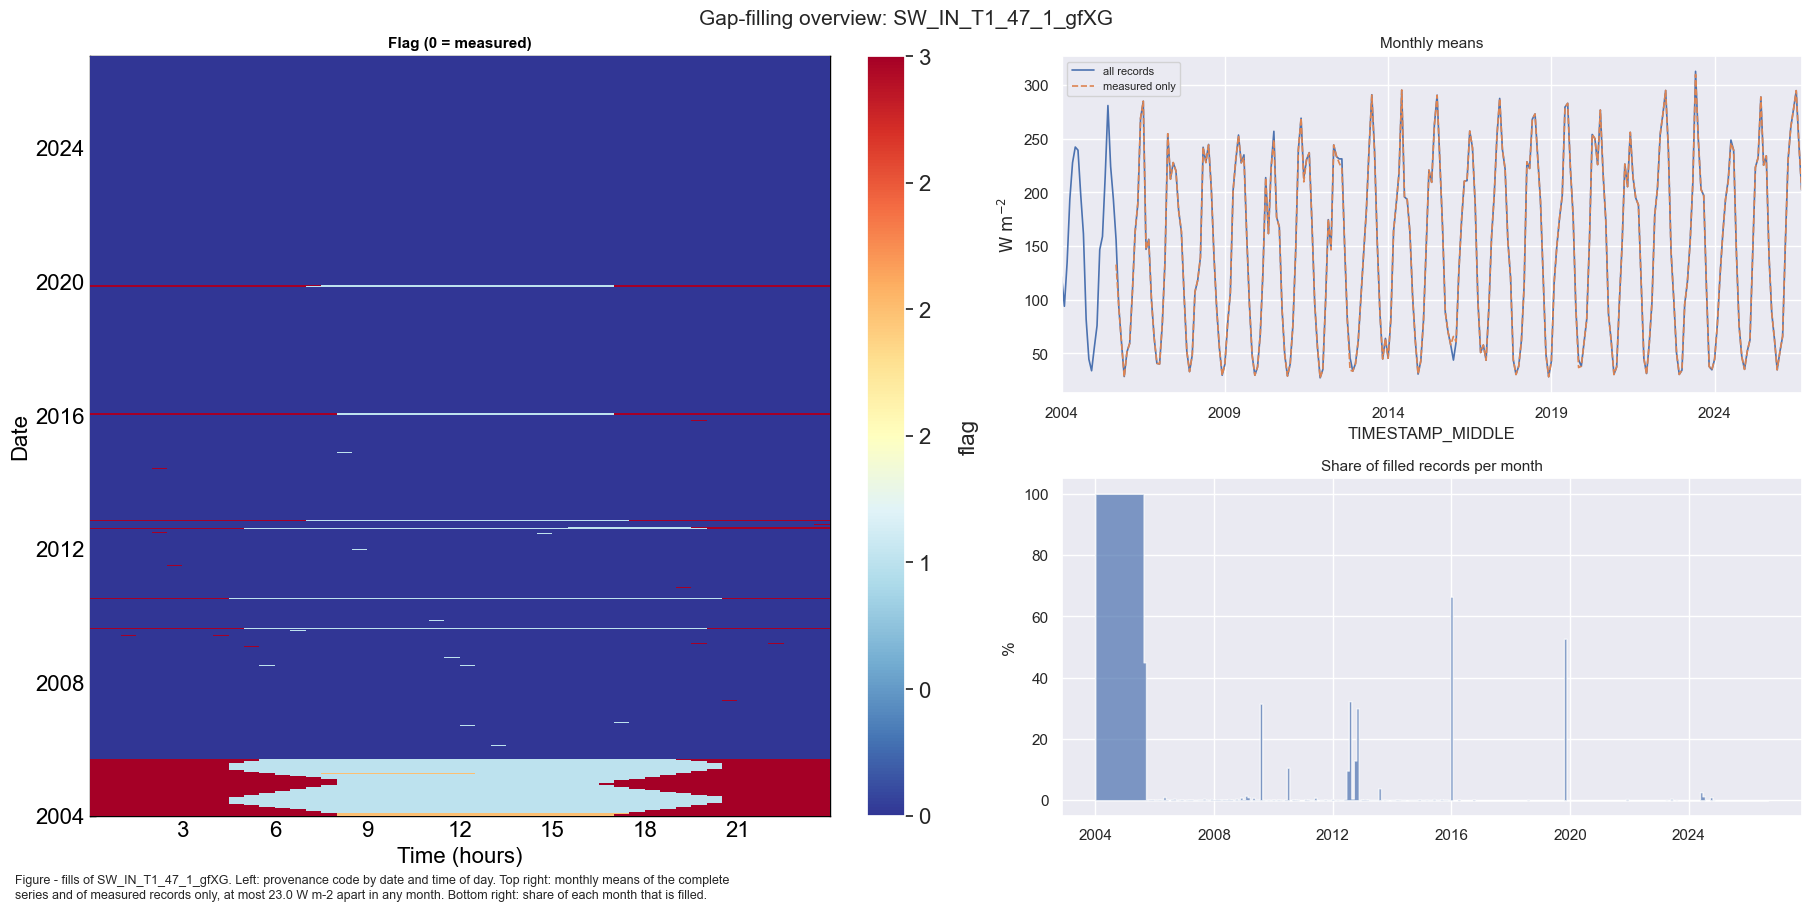

In [70]:
plot_fill_overview(export_df[VALCOL], export_df[FLAGCOL], label=VALCOL);

### 📊 📋 Plot and table: filled records per year

Records per year and flag; the bars show the filled records only.

Table - records per year and provenance code for SW_IN_T1_47_1_gfXG; each row sums to the half-hours
of that year



,0 = observed,"1 = daytime gap, filled by the XGBoost model","2 = daytime gap, filled by the timestamp-only fallback model (a driver was missing)","3 = nighttime gap, set to zero by physics"
year,,,,
2004,0,8571,598,8399
2005,5199,6863,56,5402
2006,17473,17,0,30
2007,17489,15,0,16
2008,17513,27,0,28
2009,16989,310,0,221
2010,17339,119,0,62
2011,17491,8,9,12
2012,16293,637,29,609


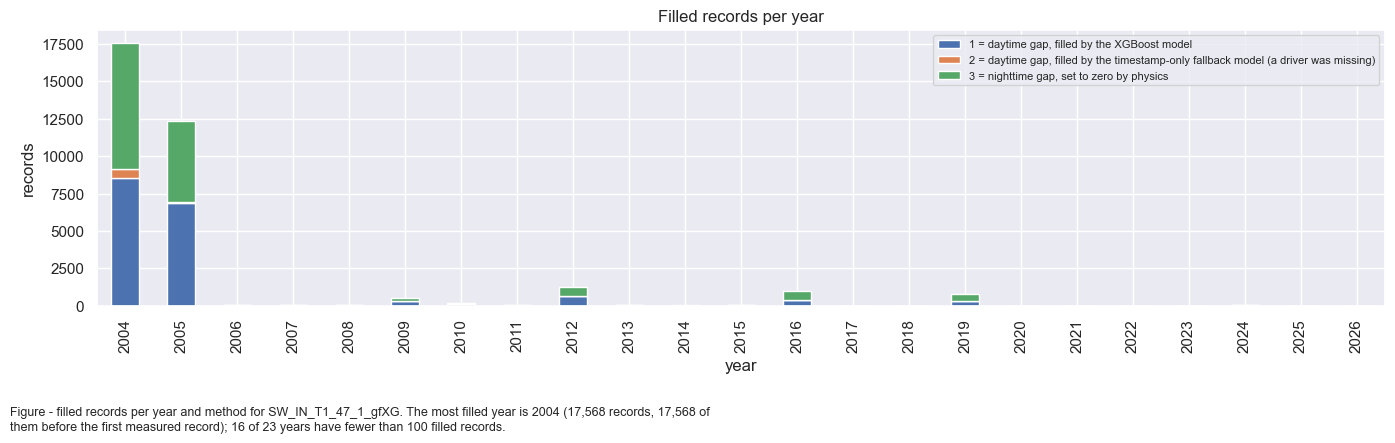

In [71]:
fill_stats_by_year(export_df[FLAGCOL], label=VALCOL)

### 📊 Plot: heatmap of the exported product

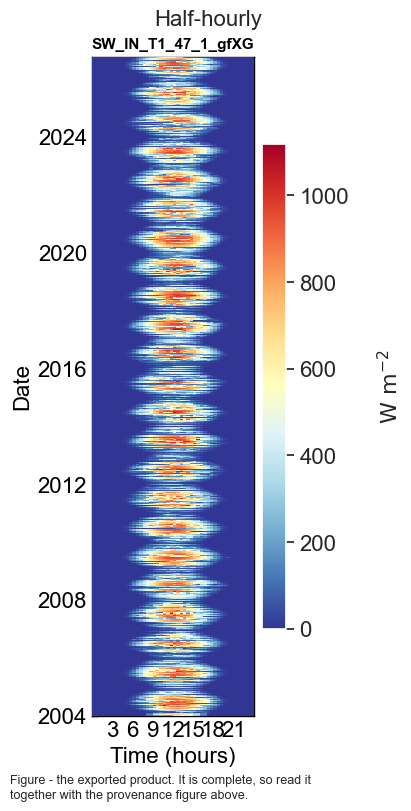

In [72]:
fig, axs = plt.subplots(ncols=1, figsize=(4, 8), dpi=100, layout="constrained")
fig.suptitle(f'Half-hourly', fontsize=16)
dv.plotting.HeatmapDateTime(series=export_df[VALCOL]).plot(
    ax=axs, cb_digits_after_comma=0, zlabel=r'$\mathrm{W\ m^{-2}}$',
    format_style=dv.plotting.FormatStyle(title=VALCOL, title_fontsize=11))
figcap(fig, "the exported product. It is complete, so read it together with the provenance "
            "figure above.")

### The exported product

The mean daily cycle through the year, and a physical-plausibility check.

#### 📊 Plot: mean daily cycle and annual means

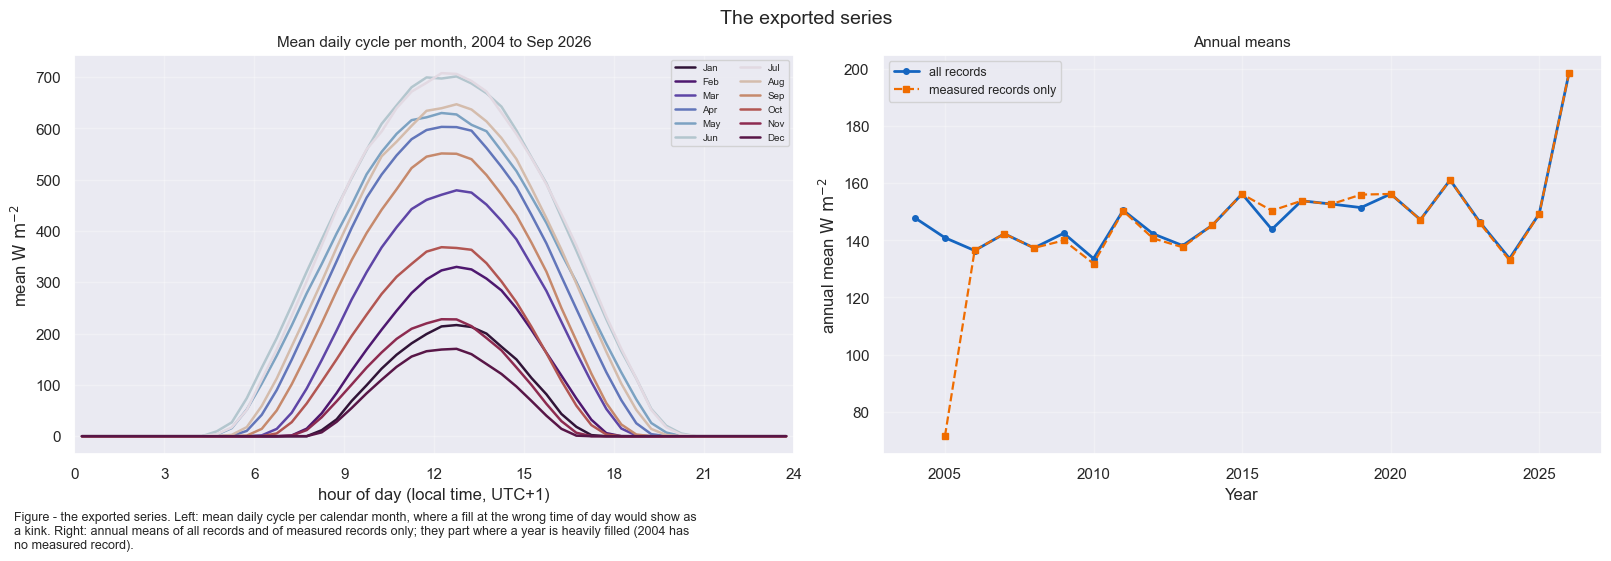

In [73]:
# The average day, month by month, and the annual cycle. This is the shape a user of the product
# will actually see, and a fill that sat at the wrong time of day would distort it.
_pot_out = dv.variables.potrad(timestamp_index=export_df.index, lat=SITE_LAT, lon=SITE_LON,
                               utc_offset=TIMEZONE_OFFSET_TO_UTC_HOURS)
_d = pd.DataFrame({'v': export_df[VALCOL], 'flag': export_df[FLAGCOL], 'pot': _pot_out})
_d['hour'] = _d.index.hour + _d.index.minute / 60
_d['month'] = _d.index.month

fig, axs = plt.subplots(ncols=2, figsize=(16, 5.5), dpi=100, layout='constrained')
fig.suptitle('The exported series', fontsize=14)

_comp = _d.pivot_table(index='hour', columns='month', values='v', aggfunc='mean')
_cmap = plt.get_cmap('twilight_shifted')
for _m in _comp.columns:
    axs[0].plot(_comp.index, _comp[_m], color=_cmap((_m - 1) / 12), lw=1.8,
                label=pd.Timestamp(2020, _m, 1).strftime('%b'))
axs[0].set_xlabel('hour of day (local time, UTC+1)')
axs[0].set_ylabel(r'mean $\mathrm{W\ m^{-2}}$')
axs[0].set_xlim(0, 24)
axs[0].set_xticks(range(0, 25, 3))
axs[0].set_title(f'Mean daily cycle per month, {_d.index[0]:%Y} to {_d.index[-1]:%b %Y}',
                 fontsize=11)
axs[0].grid(alpha=0.3)
axs[0].legend(fontsize=7, ncol=2)

_ann = _d['v'].resample('YE').mean()
_ann.index = _ann.index.year
_ann_meas = _d['v'].where(_d['flag'] == 0).resample('YE').mean()
_ann_meas.index = _ann_meas.index.year
axs[1].plot(_ann.index, _ann, color='#1565C0', lw=2, marker='o', ms=4, label='all records')
axs[1].plot(_ann_meas.index, _ann_meas, color='#EF6C00', lw=1.6, ls='--', marker='s', ms=4,
            label='measured records only')
axs[1].set_xlabel('Year')
axs[1].set_ylabel(r'annual mean $\mathrm{W\ m^{-2}}$')
axs[1].set_title('Annual means', fontsize=11)
axs[1].grid(alpha=0.3)
axs[1].legend(fontsize=9)

figcap(fig, "the exported series. Left: mean daily cycle per calendar month, where a fill at "
            "the wrong time of day would show as a kink. Right: annual means of all records and "
            "of measured records only; they part where a year is heavily filled (2004 has no "
            "measured record).")

#### 📊 Plot: physical plausibility

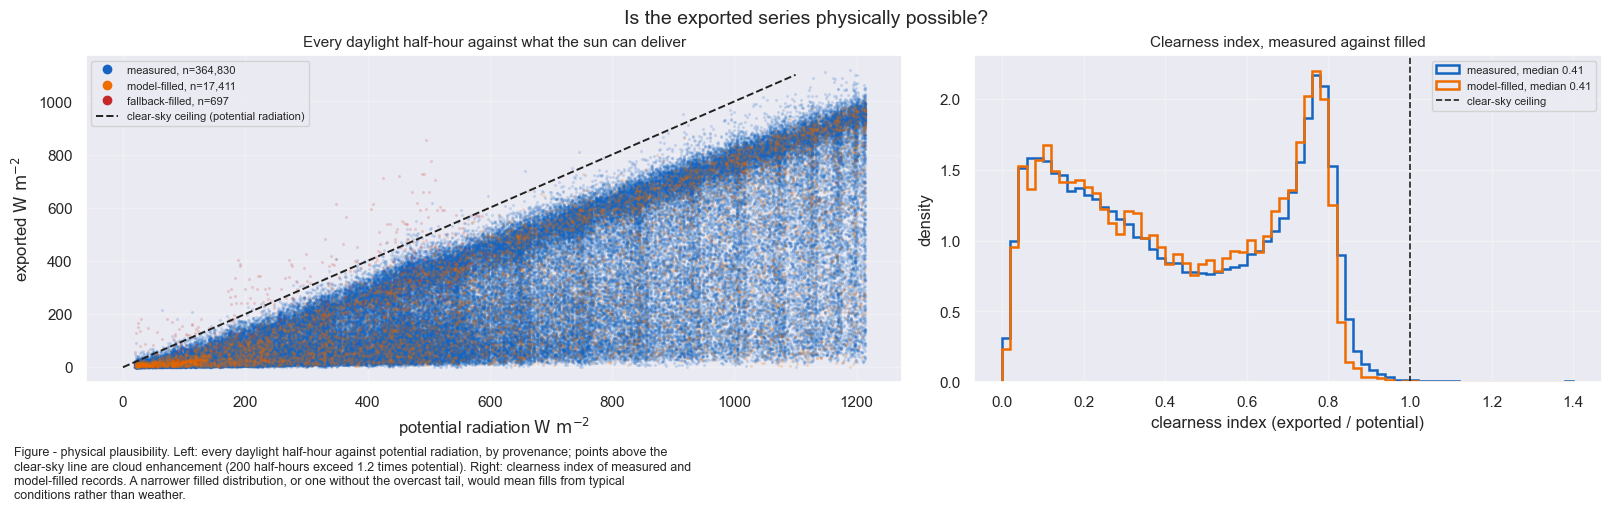

In [74]:
# A physical-plausibility check the flag counts cannot make: no half-hour may exceed what the sun
# can deliver at this latitude by more than cloud enhancement allows, and none may be negative.
_kt = (_d['v'] / _d['pot']).where(_d['pot'] > 20)
fig, axs = plt.subplots(ncols=2, figsize=(16, 5), dpi=100, layout='constrained',
                        width_ratios=[1.3, 1])
fig.suptitle('Is the exported series physically possible?', fontsize=14)

_lit_plot = _d[_d['pot'] > 20]
_sample = _lit_plot.sample(min(120_000, len(_lit_plot)), random_state=42)
for _flagval, _colour, _lab in [(0, '#1565C0', 'measured'), (1, '#EF6C00', 'model-filled'),
                                (2, '#C62828', 'fallback-filled')]:
    _s = _sample[_sample['flag'] == _flagval]
    if len(_s):
        axs[0].scatter(_s['pot'], _s['v'], s=2, alpha=0.12, color=_colour, rasterized=True)
        axs[0].plot([], [], 'o', color=_colour, label=f'{_lab}, n={int((_d["flag"] == _flagval).sum()):,}')
axs[0].plot([0, 1100], [0, 1100], color='#212121', lw=1.4, ls='--',
            label='clear-sky ceiling (potential radiation)')
axs[0].set_xlabel(r'potential radiation $\mathrm{W\ m^{-2}}$')
axs[0].set_ylabel(r'exported $\mathrm{W\ m^{-2}}$')
axs[0].set_title('Every daylight half-hour against what the sun can deliver', fontsize=11)
axs[0].legend(fontsize=8, loc='upper left')
axs[0].grid(alpha=0.25)

for _flagval, _colour, _lab in [(0, '#1565C0', 'measured'), (1, '#EF6C00', 'model-filled')]:
    _s = _kt[_d['flag'] == _flagval].dropna()
    if len(_s):
        axs[1].hist(_s.clip(0, 1.4), bins=np.linspace(0, 1.4, 71), histtype='step', lw=1.8,
                    density=True, color=_colour, label=f'{_lab}, median {_s.median():.2f}')
axs[1].axvline(1.0, color='#212121', lw=1.2, ls='--', label='clear-sky ceiling')
axs[1].set_xlabel('clearness index (exported / potential)')
axs[1].set_ylabel('density')
axs[1].set_title('Clearness index, measured against filled', fontsize=11)
axs[1].legend(fontsize=8)
axs[1].grid(alpha=0.3)

_over = int((_kt > 1.2).sum())
figcap(fig, "physical plausibility. Left: every daylight half-hour against potential "
            "radiation, by provenance; points above the clear-sky line are cloud enhancement "
            f"({_over:,} half-hours exceed 1.2 times potential). Right: clearness index of "
            "measured and model-filled records. A narrower filled distribution, or one without "
            "the overcast tail, would mean fills from typical conditions rather than weather.")

***

## 💾 Save to file

In [75]:
filepath = dv.save_parquet(filename=OUTNAME, data=export_df, outpath=OUTPATH)
export_df.to_csv(Path(OUTPATH) / f"{OUTNAME}.csv")
print(f"Saved to: {filepath}")

> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\01_METEO_SW_IN_GAPFILLED_2004-2026.09.parquet (0.051 seconds).

Saved to: F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODUCTS\01_METEO_SW_IN_GAPFILLED_2004-2026.09.parquet


### Verify the written file

The parquet file is read back and checked directly.

#### 📋 Table: yearly median and measured share, from the written file

In [76]:
_written = dv.load_parquet(filepath=str(Path(OUTPATH) / f"{OUTNAME}.parquet"))

print(f"columns:   {list(_written.columns)}")
print(f"index:     {_written.index[0]} -> {_written.index[-1]}  ({len(_written):,} records)")
print(f"measured:  {int((_written[FLAGCOL] == 0).sum()):,} "
      f"({100 * (_written[FLAGCOL] == 0).mean():.2f}%)")
print(f"median:    {float(_written[VALCOL].median()):.3f} W m-2")
print(f"min / max: {float(_written[VALCOL].min()):.3f} / {float(_written[VALCOL].max()):.3f} W m-2")

assert list(_written.columns) == [VALCOL, FLAGCOL], "unexpected columns in the written file"
assert len(_written) == len(export_df), "record count changed on write"
assert _written.index.equals(export_df.index), "index changed on write"
# The product is documented as complete and non-negative. Both claims are checked here on the file
# itself rather than on the frame that was handed to the writer.
assert _written[VALCOL].notna().all(), "the written file has gaps, but this product is exported complete"
assert float(_written[VALCOL].min()) >= 0, "negative irradiance in the written file"
assert float(_written[VALCOL].max()) < 1400, "irradiance above anything this latitude can deliver"
assert (set(_written[FLAGCOL].unique()) <= set(FLAG_LEGEND)), (
    "the written file carries a flag code that FLAG_LEGEND does not document")
print()
print("Written file verified.")

tabcap("yearly median and measured share, read back from the written parquet file")
display(pd.DataFrame({
    'yearly median (W m-2)': _written[VALCOL].groupby(_written.index.year).median().round(3),
    'measured (%)': (100 * (_written[FLAGCOL] == 0)).groupby(_written.index.year).mean().round(1),
}))

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\30_PRODU
CTS\01_METEO_SW_IN_GAPFILLED_2004-2026.09.parquet (0.012 seconds).

columns:   ['SW_IN_T1_47_1_gfXG', 'FLAG_SW_IN_T1_47_1_ISFILLED']
index:     2004-01-01 00:15:00 -> 2026-09-30 23:45:00  (398,832 records)
measured:  364,830 (91.47%)
median:    4.299 W m-2
min / max: 0.000 / 1118.658 W m-2

Written file verified.
Table - yearly median and measured share, read back from the written parquet file



,yearly median (W m-2),measured (%)
TIMESTAMP_MIDDLE,,
2004,5.554,0.0
2005,4.615,29.7
2006,3.913,99.7
2007,4.091,99.8
2008,4.203,99.7
2009,3.937,97.0
2010,3.332,99.0
2011,3.304,99.8
2012,3.440,92.7


***

## End of notebook

In [77]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-23 12:21:04
Finished: 2026-10-23 12:22:46
Runtime:  00:01:42 (hh:mm:ss)
